# 《电力市场理论及应用》课程作业：IEEE 14 全过程（第一步至第六步）

本文件包含完整 Markdown 说明、数据准备、优化建模、运行结果及图表。所有模型源代码直接嵌入本文件，**不依赖 `market_core.py`、其他 Notebook 或预先导出的 CSV**。第五步按题目要求只做数学推导。

## 本地运行

1. 将本文件保存到一个可写的本地文件夹，在 Jupyter Notebook / JupyterLab 中打开。
2. 首次运行若缺少依赖，在当前内核执行下方安装命令；安装后重启内核，再选择 **Restart Kernel and Run All**。
3. 后续输出保存在当前工作目录下的 `electricity_market_assignment_data`、`step2_results`、`step3_results`、`step4_results` 和 `step6_results`，重新运行会更新这些派生文件。

```python
%pip install pandapower==3.5.6 numpy==2.4.6 pandas==2.3.3 scipy==1.18.1 matplotlib==3.11.2
```

验证环境为 Python 3.12。Notebook 已保存执行输出，无需重跑也能阅读结果；本地重跑需要上述依赖。图表使用英文标注以避免中文字体缺失，模型说明与解释保留中文。

## 阅读顺序与假设

1. 选择 IEEE14，准备基础网络与报价、负荷和风电数据。
2. 单时段无网络约束出清，计算福利、价格与利润并验证 KKT。
3. 24 小时有/无储能出清与跨期价格分析。
4. DC 网络、节点与分区价格、容量灵敏度及物理可行性。
5. 储能及其他参与者均衡与 KKT 推导。
6. 单时段实时平衡、故障与预测偏差、两类结算。

数据来源：用户上传的《课程作业2026.pdf》和第一步 IEEE14 数据准备 Notebook。新增报价、合成风电和负荷曲线、储能参数、支路容量及故障情景均为明确的课程假设，不能当作真实市场数据。第五步原题引用“第2步中的储能”存在编号歧义，本文件采用第3步的储能模型。

In [1]:
from pathlib import Path
import importlib.util
needed = ['numpy', 'pandas', 'matplotlib', 'pandapower', 'scipy']
missing = [name for name in needed if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError('请先按首页安装命令安装缺失依赖，重启内核后从头运行：' + ', '.join(missing))
print('依赖可用。所有模型代码均在本 Notebook 内；不需要其他 Python 文件。')

依赖可用。所有模型代码均在本 Notebook 内；不需要其他 Python 文件。


# 《电力市场理论及应用》课程作业——第一步：选择算例与准备数据

**算例选择：IEEE 14 节点测试系统**

本 Notebook 只完成作业第一步：读取测试网络、检查基础数据，并为后续市场出清准备一组明确标注为“示例假设”的市场参数。此处不求解市场出清优化问题。

> 说明：IEEE 14 节点系统的原始潮流数据通常不包含完整的电力市场报价。常规机组成本、负荷报价和风电预测出力等缺失数据需要自行合理设定。后续正式计算时，应在课程作业中说明这些假设。


## 1. 安装并导入所需库

如果当前 Jupyter 环境尚未安装 `pandapower`，先运行下面的安装单元。安装后如提示重启 Kernel，请重启后从头运行 Notebook。


安装说明已统一放在本 Notebook 首页，依赖就绪后可直接运行以下单元。

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print("pandapower version:", pp.__version__)

pandapower version: 3.5.6


## 2. 读取 IEEE 14 节点测试系统

`pandapower.networks.case14()` 提供 IEEE 14 节点系统的网络模型。注意，pandapower 内部的母线索引通常从 0 开始；IEEE 算例文献中的母线编号通常从 1 开始。下面新增一列 `bus_no_ieee`，用于方便对照。


In [3]:
net = pn.case14()

# 建立 pandapower 母线索引与 IEEE 母线编号的对照。
# case14 的母线索引为 0–13，对应 IEEE 母线编号 1–14。
net.bus["bus_no_ieee"] = net.bus.index + 1

print(f"母线数量：{len(net.bus)}")
print(f"线路数量：{len(net.line)}")
print(f"变压器数量：{len(net.trafo)}")
print(f"外部电网数量：{len(net.ext_grid)}")
print(f"常规发电机数量：{len(net.gen)}")
print(f"负荷数量：{len(net.load)}")

母线数量：14
线路数量：15
变压器数量：5
外部电网数量：1
常规发电机数量：4
负荷数量：11


## 3. 查看网络基础数据

以下输出是后续建模需要核对的基础数据。不同版本的 `pandapower` 可能存在少量字段差异，因此代码只选择当前表中实际存在的列。


In [4]:
def show_columns(df, preferred_columns):
    cols = [c for c in preferred_columns if c in df.columns]
    return df[cols].copy()

bus_table = show_columns(
    net.bus,
    ["bus_no_ieee", "name", "vn_kv", "type", "zone", "in_service"]
)
gen_table = show_columns(
    net.gen,
    ["name", "bus", "p_mw", "vm_pu", "min_p_mw", "max_p_mw", "in_service"]
)
ext_grid_table = show_columns(
    net.ext_grid,
    ["name", "bus", "vm_pu", "va_degree", "in_service"]
)
load_table = show_columns(
    net.load,
    ["name", "bus", "p_mw", "q_mvar", "scaling", "in_service"]
)
line_table = show_columns(
    net.line,
    ["name", "from_bus", "to_bus", "length_km", "r_ohm_per_km",
     "x_ohm_per_km", "max_i_ka", "in_service"]
)
trafo_table = show_columns(
    net.trafo,
    ["name", "hv_bus", "lv_bus", "sn_mva", "vk_percent", "vkr_percent", "in_service"]
)

print("一、母线数据")
display(bus_table)
print("二、常规发电机数据")
display(gen_table)
print("三、外部电网数据")
display(ext_grid_table)
print("四、负荷数据")
display(load_table)
print("五、输电线路数据")
display(line_table)
print("六、变压器数据")
display(trafo_table)

一、母线数据


,bus_no_ieee,name,vn_kv,type,zone,in_service
0,1,1,135.000,b,1.0,True
1,2,2,135.000,b,1.0,True
2,3,3,135.000,b,1.0,True
3,4,4,135.000,b,1.0,True
4,5,5,135.000,b,1.0,True
5,6,6,0.208,b,1.0,True
6,7,7,14.000,b,1.0,True
7,8,8,12.000,b,1.0,True
8,9,9,0.208,b,1.0,True
9,10,10,0.208,b,1.0,True


二、常规发电机数据


,name,bus,p_mw,vm_pu,min_p_mw,max_p_mw,in_service
0,None,1,40.0,1.045,0.0,140.0,True
1,None,2,0.0,1.010,0.0,100.0,True
2,None,5,0.0,1.070,0.0,100.0,True
3,None,7,0.0,1.090,0.0,100.0,True


三、外部电网数据


...

,name,bus,p_mw,q_mvar,scaling,in_service
0,None,1,21.7,12.7,1.0,True
1,None,2,94.2,19.0,1.0,True
2,None,3,47.8,-3.9,1.0,True
3,None,4,7.6,1.6,1.0,True
4,None,5,11.2,7.5,1.0,True
5,None,8,29.5,16.6,1.0,True
6,None,9,9.0,5.8,1.0,True
7,None,10,3.5,1.8,1.0,True
8,None,11,6.1,1.6,1.0,True
9,None,12,13.5,5.8,1.0,True


五、输电线路数据


,name,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,max_i_ka,in_service
0,None,0,1,1.0,3.532005,10.783732,42.339020,True
1,None,0,4,1.0,9.846967,40.649040,42.339020,True
2,None,1,2,1.0,8.563928,36.080033,42.339020,True
3,None,1,3,1.0,10.590547,32.134320,42.339020,True
4,None,1,4,1.0,10.379138,31.689630,42.339020,True
5,None,2,3,1.0,12.212573,31.170217,42.339020,True
6,None,3,4,1.0,2.433038,7.674548,42.339020,True
7,None,5,10,1.0,0.000041,0.000086,27479.652235,True
8,None,5,11,1.0,0.000053,0.000111,27479.652235,True
9,None,5,12,1.0,0.000029,0.000056,27479.652235,True


六、变压器数据


,name,hv_bus,lv_bus,sn_mva,vk_percent,vkr_percent,in_service
0,None,3,6,9900.0,2070.288,0.0,True
1,None,3,8,9900.0,5506.182,0.0,True
2,None,4,5,9900.0,2494.998,0.0,True
3,None,6,7,9900.0,1743.885,0.0,True
4,None,6,8,9900.0,1089.099,0.0,True


## 4. 统计系统规模

这里统计网络中已录入的有功负荷。该统计用于核对数据，并不代表市场出清后的实际供电量。


In [5]:
total_load_mw = net.load.loc[net.load["in_service"], "p_mw"].sum()
total_gen_max_mw = (
    net.gen.loc[net.gen["in_service"], "max_p_mw"].sum()
    if "max_p_mw" in net.gen.columns
    else np.nan
)

summary = pd.DataFrame({
    "指标": ["母线数", "线路数", "变压器数", "常规发电机数", "负荷点数", "原始有功负荷合计 (MW)"],
    "数值": [
        len(net.bus), len(net.line), len(net.trafo),
        len(net.gen) + len(net.ext_grid), len(net.load), total_load_mw
    ]
})
display(summary)

print("注意：外部电网在潮流模型中代表平衡节点；在后续市场模型中，需要明确是否将其视为可报价的常规机组。")

,指标,数值
0,母线数,14.0
1,线路数,15.0
2,变压器数,5.0
3,常规发电机数,5.0
4,负荷点数,11.0
5,原始有功负荷合计 (MW),259.0


注意：外部电网在潮流模型中代表平衡节点；在后续市场模型中，需要明确是否将其视为可报价的常规机组。


## 5. 为后续市场出清补充示例市场参数

原始 IEEE 14 节点网络不提供完整的市场报价曲线。下面给出一组**仅用于演示数据结构的假设值**：

- 常规机组：使用边际成本（€/MWh）作为简化的发电报价。
- 价格弹性负荷：使用高于常规机组成本的效用报价，确保负荷有较强的供电意愿。
- 风电场：假设设置在 IEEE 母线 6 和 8；预测出力随时段变化，生产成本按作业要求设为 0 €/MWh。

这些值是建模假设，不是 IEEE 原始数据或真实市场报价。为避免把外部电网的平衡注入误当成普通报价机组，本示例将 `net.gen` 中的常规机组单独整理；后续建立市场模型时，应进一步为母线 1 的发电资源明确容量、成本和报价假设。


In [6]:
# 常规机组的简化示例报价。请在正式作业中说明这是自行设定的假设。
# 若当前数据中的机组数量或排序不同，请结合上方 gen_table 核对并调整。
conventional_generators = net.gen.copy()
conventional_generators["bus_no_ieee"] = conventional_generators["bus"].astype(int) + 1
conventional_generators["marginal_cost_eur_per_mwh"] = [20, 25, 35, 40, 45][:len(conventional_generators)]
conventional_generators["offer_price_eur_per_mwh"] = conventional_generators["marginal_cost_eur_per_mwh"]

display(conventional_generators[
    ["bus_no_ieee", "p_mw", "marginal_cost_eur_per_mwh", "offer_price_eur_per_mwh"]
])

,bus_no_ieee,p_mw,marginal_cost_eur_per_mwh,offer_price_eur_per_mwh
0,2,40.0,20,20
1,3,0.0,25,25
2,6,0.0,35,35
3,8,0.0,40,40


In [7]:
# 负荷报价示例：取相对较高的效用报价。
# 注意：这里把每个原始负荷点视作一个简化的价格弹性负荷块。
load_bids = net.load.copy()
load_bids["bus_no_ieee"] = load_bids["bus"].astype(int) + 1
load_bids["demand_mw"] = load_bids["p_mw"] * load_bids.get("scaling", 1.0)
load_bids["utility_bid_eur_per_mwh"] = 200.0

display(load_bids[
    ["bus_no_ieee", "demand_mw", "utility_bid_eur_per_mwh"]
])

,bus_no_ieee,demand_mw,utility_bid_eur_per_mwh
0,2,21.7,200.0
1,3,94.2,200.0
2,4,47.8,200.0
3,5,7.6,200.0
4,6,11.2,200.0
5,9,29.5,200.0
6,10,9.0,200.0
7,11,3.5,200.0
8,12,6.1,200.0
9,13,13.5,200.0


## 6. 构造 24 小时风电预测数据（示例假设）

作业允许使用外部风电数据，也允许对缺失数据作合理假设。这里先构造一组可重复生成的合成预测曲线，供后续多时段建模练习使用。正式报告中必须明确说明：这不是实测风电数据。


,hour,wind_bus6_forecast_mw,wind_bus8_forecast_mw,total_wind_forecast_mw
0,1,13.14,20.63,33.76
1,2,17.48,24.01,41.49
2,3,15.86,21.09,36.95
3,4,25.29,25.11,50.40
4,5,26.62,21.23,47.86
5,6,27.42,23.23,50.65
6,7,29.65,20.36,50.02
7,8,32.63,23.25,55.89
8,9,32.59,20.93,53.52
9,10,33.05,19.68,52.73


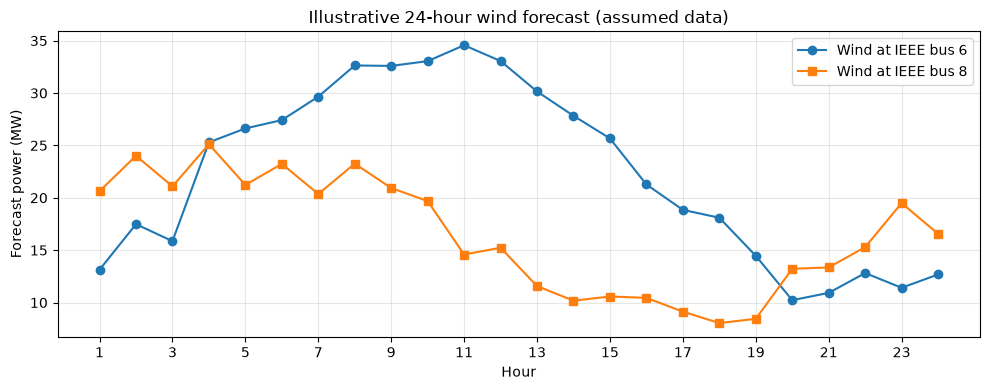

In [8]:
hours = np.arange(1, 25)

# 示例：两个风电场分别设置装机容量，使用平滑且不完全相同的归一化出力曲线。
# 固定随机种子，保证每次运行结果一致。
rng = np.random.default_rng(2026)

wind_capacity_mw = {
    6: 50.0,  # IEEE 母线 6，假设风电装机 50 MW
    8: 40.0,  # IEEE 母线 8，假设风电装机 40 MW
}

profile_6 = 0.45 + 0.22 * np.sin(2 * np.pi * (hours - 4) / 24) + rng.normal(0, 0.04, 24)
profile_8 = 0.40 + 0.18 * np.sin(2 * np.pi * (hours + 1) / 24) + rng.normal(0, 0.04, 24)

profile_6 = np.clip(profile_6, 0.05, 0.95)
profile_8 = np.clip(profile_8, 0.05, 0.95)

wind_forecast = pd.DataFrame({
    "hour": hours,
    "wind_bus6_forecast_mw": wind_capacity_mw[6] * profile_6,
    "wind_bus8_forecast_mw": wind_capacity_mw[8] * profile_8,
})
wind_forecast["total_wind_forecast_mw"] = (
    wind_forecast["wind_bus6_forecast_mw"] + wind_forecast["wind_bus8_forecast_mw"]
)

display(wind_forecast.round(2))

plt.figure(figsize=(10, 4))
plt.plot(wind_forecast["hour"], wind_forecast["wind_bus6_forecast_mw"], marker="o", label="Wind at IEEE bus 6")
plt.plot(wind_forecast["hour"], wind_forecast["wind_bus8_forecast_mw"], marker="s", label="Wind at IEEE bus 8")
plt.xlabel("Hour")
plt.ylabel("Forecast power (MW)")
plt.title("Illustrative 24-hour wind forecast (assumed data)")
plt.xticks(range(1, 25, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 7. 绘制网络拓扑图

使用 NetworkX 绘制第一步全部线路和变压器连接关系。这是示意布局，不代表地理坐标；固定种子使布局可重复。

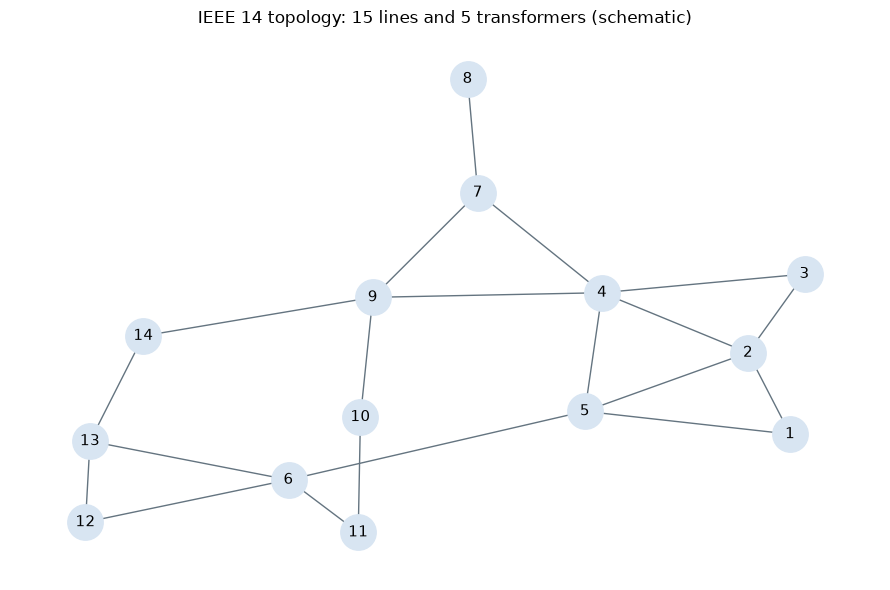

In [9]:
# 使用 NetworkX 绘制全部线路与变压器，无需额外的地图/拓扑绘图库。
import networkx as nx
G_ieee14 = nx.Graph()
G_ieee14.add_nodes_from(range(1, 15))
G_ieee14.add_edges_from((int(r.from_bus)+1, int(r.to_bus)+1) for _, r in net.line.iterrows())
G_ieee14.add_edges_from((int(r.hv_bus)+1, int(r.lv_bus)+1) for _, r in net.trafo.iterrows())
assert G_ieee14.number_of_nodes() == 14 and G_ieee14.number_of_edges() == 20
positions = nx.spring_layout(G_ieee14, seed=2026)
fig, ax = plt.subplots(figsize=(9, 6))
nx.draw_networkx(G_ieee14, pos=positions, ax=ax, node_color='#d8e5f2',
                 edge_color='#647480', node_size=650, font_size=11)
ax.set_title('IEEE 14 topology: 15 lines and 5 transformers (schematic)')
ax.axis('off'); fig.tight_layout(); plt.show()

## 8. 保存基础数据，供后续步骤使用

CSV 文件便于检查和复用；`pandapower` 网络对象也可以保存为 JSON。后续建立市场出清优化模型时，可以从这些数据表读取报价、负荷和风电预测值。


In [10]:
from pathlib import Path

output_dir = Path("electricity_market_assignment_data")
output_dir.mkdir(exist_ok=True)

bus_table.to_csv(output_dir / "ieee14_buses.csv", index=False, encoding="utf-8-sig")
gen_table.to_csv(output_dir / "ieee14_generators.csv", index=False, encoding="utf-8-sig")
load_bids.to_csv(output_dir / "ieee14_load_bids.csv", index=False, encoding="utf-8-sig")
line_table.to_csv(output_dir / "ieee14_lines.csv", index=False, encoding="utf-8-sig")
wind_forecast.to_csv(output_dir / "wind_forecast_24h_assumed.csv", index=False, encoding="utf-8-sig")
pp.to_json(net, str(output_dir / "ieee14_network.json"))

print("数据已保存到：", output_dir.resolve())
print("注意：保存的风电与市场报价数据属于示例假设，后续请根据模型需要进一步校验和调整。")

数据已保存到： /workspace/python-power-market-coursework-2026/electricity_market_assignment_data
注意：保存的风电与市场报价数据属于示例假设，后续请根据模型需要进一步校验和调整。


## 第一步完成情况与下一步

本 Notebook 已完成：
1. 选择并读取 IEEE 14 节点测试系统；
2. 查看母线、机组、负荷、线路和变压器数据；
3. 给出示例常规机组报价、负荷效用报价；
4. 生成示例 24 小时风电预测数据；
5. 保存基础数据。

**下一步（作业第二步）**才是建立无网络约束、单时段的市场出清优化模型，求解社会福利最大化，并计算统一市场出清价格、发电商利润和负荷效用。届时需要特别处理市场出清价格与优化问题对偶变量的对应关系，并按作业要求用 KKT 条件进行验证。


---
# 第二步：无约束单时段市场出清
以下单元在本文件中重建第二步输入，不依赖第一步的隐藏内存状态。

# 第二步：无约束单时段市场出清（IEEE 14）

本 Notebook 对应《课程作业2026.pdf》第二步：福利最大化、统一电价、社会福利、各常规机组和风电场利润、各负荷效用，以及完整 KKT 数值验证。使用 SciPy/HiGHS 线性规划，无需商业求解器。

**数据衔接**：按上传的《课程作业_第一步_IEEE14数据准备.ipynb》重新构造同一组输入，不依赖另一个 Notebook 的内存状态，也不要求先复制 CSV。第一步导出的 `ieee14_generators.csv` 不含后来新增的报价列，因此此处显式恢复报价，避免静默丢失成本。两个风电场的随机种子、曲线和容量完全沿用第一步。

本步不考虑输电、网损、机组启停、爬坡、储能或多时段耦合；IEEE 母线编号仅用于标识参与者。

## 1. 环境与参数

首次运行若缺包，请在当前内核执行 `%pip install pandapower numpy pandas scipy`，必要时重启内核。默认选择第一步风电预测的第 12 小时，单时段长度为 1 小时；可修改 `SELECTED_HOUR` 后从头运行。

### 建模假设

- 常规机组报价等于恒定边际成本，沿用第一步按 `net.gen` 顺序给定的 20、25、35、40 €/MWh。
- 将母线 1 的外部电网等效为一个常规报价机组：上限读取 case14 的 `max_p_mw`，若缺失才采用明确的 332.4 MW 假设；成本/报价新增假设为 30 €/MWh。不允许无限外部购电。
- 所有机组下限取 0，不强制按潮流工况发电；最大出力为市场报量。
- 每个原始负荷点为一个价格弹性需求块，上限为第一步的 `p_mw × scaling`，报价 200 €/MWh。
- 风电报价及生产成本为 0，报量为所选小时的合成预测；允许弃风。
- 货币以欧元表示，功率 MW，价格 €/MWh；利润、效用和福利均乘以时段长度，单位 €。不含固定、启动和空载成本，故这里的利润是变动成本口径的利润。

In [11]:
from pathlib import Path
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import pandapower.networks as pn
from scipy.optimize import linprog
from IPython.display import display

SELECTED_HOUR = 12
DURATION_HOURS = 1.0
BUS1_COST = 30.0
TOL = 1e-6
assert 1 <= SELECTED_HOUR <= 24
assert DURATION_HOURS > 0
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.6f}")
print("Python:", sys.version.split()[0])
print({p: metadata.version(p) for p in ["pandapower", "numpy", "pandas", "scipy"]})

Python: 3.12.14
{'pandapower': '3.5.6', 'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.18.1'}


## 2. 重建第一步输入并补充母线 1 机组
不使用潮流工况的 `p_mw` 作为必须发电量。当前发电量由出清模型决定。

In [12]:
net = pn.case14()
assert len(net.gen) == 4, "算例发生变化，请重新核对第一步成本与机组对应关系。"
gen = net.gen.loc[net.gen.in_service].copy()
assert len(gen) == 4
cost_by_index = dict(zip(net.gen.index, [20., 25., 35., 40.]))
conventional = pd.DataFrame({
    "id": [f"G_bus{int(b)+1}" for b in gen.bus],
    "bus": gen.bus.astype(int).to_numpy() + 1,
    "capacity_mw": gen.max_p_mw.to_numpy(dtype=float),
    "cost": [cost_by_index[i] for i in gen.index],
})
ext = net.ext_grid.loc[net.ext_grid.in_service]
assert len(ext) == 1 and int(ext.iloc[0].bus) == 0
bus1_capacity = float(ext.iloc[0].get("max_p_mw", np.nan))
capacity_source = "case14 ext_grid.max_p_mw"
if not np.isfinite(bus1_capacity):
    bus1_capacity = 332.4
    capacity_source = "缺失容量的补充假设"
conventional = pd.concat([pd.DataFrame([{
    "id": "G_bus1", "bus": 1, "capacity_mw": bus1_capacity, "cost": BUS1_COST,
}]), conventional], ignore_index=True)
conventional["offer"] = conventional.cost
conventional["type"] = "conventional"
print(f"母线1上限：{bus1_capacity} MW；来源：{capacity_source}；报价：{BUS1_COST} €/MWh")
display(conventional)

load = net.load.loc[net.load.in_service].copy()
loads = pd.DataFrame({
    "id": [f"D_bus{int(b)+1}" for b in load.bus],
    "bus": load.bus.astype(int).to_numpy() + 1,
    "capacity_mw": (load.p_mw * load.scaling).to_numpy(dtype=float),
    "bid": 200.0,
})
hours = np.arange(1, 25)
rng = np.random.default_rng(2026)
profile6 = np.clip(0.45 + 0.22*np.sin(2*np.pi*(hours-4)/24) + rng.normal(0, 0.04, 24), 0.05, 0.95)
profile8 = np.clip(0.40 + 0.18*np.sin(2*np.pi*(hours+1)/24) + rng.normal(0, 0.04, 24), 0.05, 0.95)
wind_forecast = pd.DataFrame({"hour": hours, "wind_bus6_forecast_mw": 50*profile6,
                              "wind_bus8_forecast_mw": 40*profile8})
selected = wind_forecast.set_index("hour").loc[SELECTED_HOUR]
wind = pd.DataFrame({"id": ["W_bus6", "W_bus8"], "bus": [6, 8],
    "capacity_mw": [selected.wind_bus6_forecast_mw, selected.wind_bus8_forecast_mw],
    "cost": [0., 0.], "offer": [0., 0.], "type": ["wind", "wind"]})
supply = pd.concat([conventional, wind], ignore_index=True)
for table, price_column in [(supply, "offer"), (loads, "bid")]:
    assert table.id.is_unique
    assert np.isfinite(table[["capacity_mw", price_column]].to_numpy()).all()
    assert (table.capacity_mw > 0).all()
assert np.isfinite(supply.cost).all()
display(wind)
display(loads)
print(f"选择小时：{SELECTED_HOUR}；需求报量：{loads.capacity_mw.sum():.3f} MW；风电预测：{wind.capacity_mw.sum():.3f} MW")

母线1上限：332.40000000000003 MW；来源：case14 ext_grid.max_p_mw；报价：30.0 €/MWh


,id,bus,capacity_mw,cost,offer,type
0,G_bus1,1,332.400000,30.000000,30.000000,conventional
1,G_bus2,2,140.000000,20.000000,20.000000,conventional
2,G_bus3,3,100.000000,25.000000,25.000000,conventional
3,G_bus6,6,100.000000,35.000000,35.000000,conventional
4,G_bus8,8,100.000000,40.000000,40.000000,conventional


,id,bus,capacity_mw,cost,offer,type
0,W_bus6,6,33.055690,0.000000,0.000000,wind
1,W_bus8,8,15.231791,0.000000,0.000000,wind


,id,bus,capacity_mw,bid
0,D_bus2,2,21.700000,200.000000
1,D_bus3,3,94.200000,200.000000
2,D_bus4,4,47.800000,200.000000
3,D_bus5,5,7.600000,200.000000
4,D_bus6,6,11.200000,200.000000
5,D_bus9,9,29.500000,200.000000
6,D_bus10,10,9.000000,200.000000
7,D_bus11,11,3.500000,200.000000
8,D_bus12,12,6.100000,200.000000
9,D_bus13,13,13.500000,200.000000


选择小时：12；需求报量：259.000 MW；风电预测：48.287 MW


## 3. 社会福利最大化模型与价格符号

令 $p_i$ 为常规机组及风电出清功率，$d_j$ 为负荷出清功率，报价分别为 $c_i,b_j$，容量上限为 $\bar P_i,\bar D_j$，时段长度为 $\Delta t$。

$$\max_{p,d}\quad SW=\Delta t\left(\sum_j b_jd_j-\sum_i c_ip_i\right)$$
$$\sum_jd_j-\sum_ip_i=0,\qquad 0\le p_i\le\bar P_i,\quad 0\le d_j\le\bar D_j.$$

SciPy 求解最小化 $-SW$，变量顺序为 $x=[p,d]$，等式行为 $[-\mathbf1,+\mathbf1]x=0$。`eqlin.marginals` 是最小化目标对等式右端的导数，因此 **价格 $\lambda=-\mathrm{marginal}/\Delta t$**。

后面通过 KKT 和有限差分同时检查符号，避免直接将对偶值误当成电价。

In [13]:
ng, nd = len(supply), len(loads)
capacity = np.r_[supply.capacity_mw.to_numpy(), loads.capacity_mw.to_numpy()]
objective = DURATION_HOURS * np.r_[supply.offer.to_numpy(), -loads.bid.to_numpy()]
Aeq = np.r_[-np.ones(ng), np.ones(nd)].reshape(1, -1)
bounds = [(0.0, float(u)) for u in capacity]

def clear_market(balance_rhs=0.0):
    result = linprog(objective, A_eq=Aeq, b_eq=[balance_rhs], bounds=bounds, method="highs")
    if not result.success:
        raise RuntimeError(f"出清失败：status={result.status}, {result.message}")
    return result

result = clear_market()
p = result.x[:ng]
d = result.x[ng:]
price = -float(result.eqlin.marginals[0]) / DURATION_HOURS
welfare = -float(result.fun)
print(result.message)
print(f"统一出清电价：{price:.6f} €/MWh")
print(f"社会福利：{welfare:.6f} €（时段长度 {DURATION_HOURS:g} h）")
print(f"供给 = {p.sum():.6f} MW；需求 = {d.sum():.6f} MW")

Optimization terminated successfully. (HiGHS Status 7: Optimal)
统一出清电价：25.000000 €/MWh
社会福利：47232.187019 €（时段长度 1 h）
供给 = 259.000000 MW；需求 = 259.000000 MW


## 4. 各发电商利润与各负荷效用
发电利润 = 收入 − 变动成本；负荷效用按作业定义为消费者剩余，即用电量 ×（报价 − 出清价）× 时段长度。总支付为市场参与者之间的转移，不应再次计入社会福利。

In [14]:
generator_results = supply.copy()
generator_results["dispatch_mw"] = p
generator_results["unused_mw"] = supply.capacity_mw - p
generator_results["revenue_eur"] = price * p * DURATION_HOURS
generator_results["variable_cost_eur"] = supply.cost * p * DURATION_HOURS
generator_results["profit_eur"] = generator_results.revenue_eur - generator_results.variable_cost_eur
load_results = loads.copy()
load_results["served_mw"] = d
load_results["unserved_mw"] = loads.capacity_mw - d
load_results["gross_value_eur"] = loads.bid * d * DURATION_HOURS
load_results["payment_eur"] = price * d * DURATION_HOURS
load_results["utility_eur"] = (loads.bid - price) * d * DURATION_HOURS
print("所有常规机组及风电场：")
display(generator_results)
print("所有负荷：")
display(load_results)
summary = pd.Series({
    "price_eur_per_mwh": price,
    "social_welfare_eur": welfare,
    "conventional_profit_eur": generator_results.loc[generator_results.type.eq("conventional"), "profit_eur"].sum(),
    "wind_profit_eur": generator_results.loc[generator_results.type.eq("wind"), "profit_eur"].sum(),
    "load_utility_eur": load_results.utility_eur.sum(),
    "supply_mw": p.sum(), "demand_mw": d.sum(),
    "unserved_mw": load_results.unserved_mw.sum(),
}, name="result")
display(summary.to_frame())
assert abs(welfare - generator_results.profit_eur.sum() - load_results.utility_eur.sum()) < TOL
assert abs(generator_results.revenue_eur.sum() - load_results.payment_eur.sum()) < TOL
print("福利 = 生产者利润 + 消费者剩余；总购电支付 = 总售电收入：均通过。")

所有常规机组及风电场：


,id,bus,capacity_mw,cost,offer,type,dispatch_mw,unused_mw,revenue_eur,variable_cost_eur,profit_eur
0,G_bus1,1,332.400000,30.000000,30.000000,conventional,0.000000,332.400000,0.000000,0.000000,0.000000
1,G_bus2,2,140.000000,20.000000,20.000000,conventional,140.000000,0.000000,"3,500.000000","2,800.000000",700.000000
2,G_bus3,3,100.000000,25.000000,25.000000,conventional,70.712519,29.287481,"1,767.812981","1,767.812981",0.000000
3,G_bus6,6,100.000000,35.000000,35.000000,conventional,0.000000,100.000000,0.000000,0.000000,0.000000
4,G_bus8,8,100.000000,40.000000,40.000000,conventional,0.000000,100.000000,0.000000,0.000000,0.000000
5,W_bus6,6,33.055690,0.000000,0.000000,wind,33.055690,0.000000,826.392246,0.000000,826.392246
6,W_bus8,8,15.231791,0.000000,0.000000,wind,15.231791,0.000000,380.794773,0.000000,380.794773


所有负荷：


,id,bus,capacity_mw,bid,served_mw,unserved_mw,gross_value_eur,payment_eur,utility_eur
0,D_bus2,2,21.700000,200.000000,21.700000,0.000000,"4,340.000000",542.500000,"3,797.500000"
1,D_bus3,3,94.200000,200.000000,94.200000,0.000000,"18,840.000000","2,355.000000","16,485.000000"
2,D_bus4,4,47.800000,200.000000,47.800000,0.000000,"9,560.000000","1,195.000000","8,365.000000"
3,D_bus5,5,7.600000,200.000000,7.600000,0.000000,"1,520.000000",190.000000,"1,330.000000"
4,D_bus6,6,11.200000,200.000000,11.200000,0.000000,"2,240.000000",280.000000,"1,960.000000"
5,D_bus9,9,29.500000,200.000000,29.500000,0.000000,"5,900.000000",737.500000,"5,162.500000"
6,D_bus10,10,9.000000,200.000000,9.000000,0.000000,"1,800.000000",225.000000,"1,575.000000"
7,D_bus11,11,3.500000,200.000000,3.500000,0.000000,700.000000,87.500000,612.500000
8,D_bus12,12,6.100000,200.000000,6.100000,0.000000,"1,220.000000",152.500000,"1,067.500000"
9,D_bus13,13,13.500000,200.000000,13.500000,0.000000,"2,700.000000",337.500000,"2,362.500000"


,result
price_eur_per_mwh,25.000000
social_welfare_eur,"47,232.187019"
conventional_profit_eur,700.000000
wind_profit_eur,"1,207.187019"
load_utility_eur,"45,325.000000"
supply_mw,259.000000
demand_mw,259.000000
unserved_mw,0.000000


福利 = 生产者利润 + 消费者剩余；总购电支付 = 总售电收入：均通过。


## 5. KKT 推导及逐项数值验证

对最小化问题使用拉格朗日函数（保留经济价格符号）：

$$L=\Delta t\left(\sum_i c_ip_i-\sum_j b_jd_j\right)
+\Delta t\lambda\left(\sum_j d_j-\sum_i p_i\right)
+\alpha^T(-x)+\beta^T(x-\bar x).$$

KKT 条件：

1. 原始可行：功率平衡及所有上下界。
2. 对偶可行：$\alpha,\beta\ge0$。
3. 驻点：发电 $\Delta t(c_i-\lambda)-\alpha_i+\beta_i=0$；负荷 $\Delta t(\lambda-b_j)-\alpha_j+\beta_j=0$。
4. 互补松弛：$\alpha_kx_k=0$，$\beta_k(\bar x_k-x_k)=0$。

SciPy 的下界 marginal 对应 $\alpha$，上界 marginal 对应 $-\beta$，等式 marginal 对应 $-\Delta t\lambda$。这是连续线性规划，KKT 可行解即全局最优解；同时检查原始目标与对偶目标相等。

经济含义：未出清机组报价不低于价格，满发机组报价不高于价格，部分出清机组报价等于价格。对需求则方向相反。

In [15]:
x = result.x
alpha = np.asarray(result.lower.marginals)
beta = -np.asarray(result.upper.marginals)
stationarity = objective + DURATION_HOURS * price * Aeq.ravel() - alpha + beta
balance_error = abs(float((Aeq @ x)[0]))
bound_violation = max(0., float((-x).max()), float((x-capacity).max()))
dual_violation = max(0., float((-alpha).max()), float((-beta).max()))
lower_complementarity = alpha*x
upper_complementarity = beta*(capacity-x)
dual_objective = -float(beta @ capacity)  # 平衡右端和所有下界均为0
checks = pd.Series({
    "power_balance_residual_MW": balance_error,
    "bound_violation_MW": bound_violation,
    "dual_nonnegativity_violation": dual_violation,
    "stationarity_max_abs": np.max(np.abs(stationarity)),
    "lower_complementarity_max_abs": np.max(np.abs(lower_complementarity)),
    "upper_complementarity_max_abs": np.max(np.abs(upper_complementarity)),
    "primal_dual_objective_gap_eur": abs(result.fun - dual_objective),
})
display(checks.to_frame("absolute_residual"))
assert (checks < TOL).all(), "KKT验证未通过，请检查输入与符号。"
kkt_table = pd.DataFrame({
    "id": list(supply.id) + list(loads.id), "x_mw": x, "upper_mw": capacity,
    "alpha_lower": alpha, "beta_upper": beta,
    "stationarity_residual": stationarity,
    "alpha_x": lower_complementarity, "beta_slack": upper_complementarity,
})
print("供给方 KKT：")
display(kkt_table.iloc[:ng])
print("需求方 KKT：")
display(kkt_table.iloc[ng:])
print("KKT全部通过。")

,absolute_residual
power_balance_residual_MW,0.000000
bound_violation_MW,0.000000
dual_nonnegativity_violation,0.000000
stationarity_max_abs,0.000000
lower_complementarity_max_abs,0.000000
upper_complementarity_max_abs,0.000000
primal_dual_objective_gap_eur,0.000000


供给方 KKT：


,id,x_mw,upper_mw,alpha_lower,beta_upper,stationarity_residual,alpha_x,beta_slack
0,G_bus1,0.000000,332.400000,5.000000,-0.000000,0.000000,0.000000,-0.000000
1,G_bus2,140.000000,140.000000,0.000000,5.000000,0.000000,0.000000,0.000000
2,G_bus3,70.712519,100.000000,0.000000,-0.000000,0.000000,0.000000,-0.000000
3,G_bus6,0.000000,100.000000,10.000000,-0.000000,0.000000,0.000000,-0.000000
4,G_bus8,0.000000,100.000000,15.000000,-0.000000,0.000000,0.000000,-0.000000
5,W_bus6,33.055690,33.055690,0.000000,25.000000,0.000000,0.000000,0.000000
6,W_bus8,15.231791,15.231791,0.000000,25.000000,0.000000,0.000000,0.000000


需求方 KKT：


,id,x_mw,upper_mw,alpha_lower,beta_upper,stationarity_residual,alpha_x,beta_slack
7,D_bus2,21.700000,21.700000,0.000000,175.000000,0.000000,0.000000,0.000000
8,D_bus3,94.200000,94.200000,0.000000,175.000000,0.000000,0.000000,0.000000
9,D_bus4,47.800000,47.800000,0.000000,175.000000,0.000000,0.000000,0.000000
10,D_bus5,7.600000,7.600000,0.000000,175.000000,0.000000,0.000000,0.000000
11,D_bus6,11.200000,11.200000,0.000000,175.000000,0.000000,0.000000,0.000000
12,D_bus9,29.500000,29.500000,0.000000,175.000000,0.000000,0.000000,0.000000
13,D_bus10,9.000000,9.000000,0.000000,175.000000,0.000000,0.000000,0.000000
14,D_bus11,3.500000,3.500000,0.000000,175.000000,0.000000,0.000000,0.000000
15,D_bus12,6.100000,6.100000,0.000000,175.000000,0.000000,0.000000,0.000000
16,D_bus13,13.500000,13.500000,0.000000,175.000000,0.000000,0.000000,0.000000


KKT全部通过。


## 6. 用边际参与者和有限差分再次核对价格

当存在部分出清的发电或负荷报价块时，其报价必须等于价格。若全部变量都处在边界，价格可能只由区间确定、并不唯一，不能强行指定某台满发机组为唯一边际机组。

以下由每个参与者的出清状态构造支持当前解的价格区间。将平衡等式右端减少少量 ε（即 $\sum d-\sum p=-\varepsilon$），代表系统需要额外供应 ε MW 的外生负荷；其导致的最小化目标增量除以 ε 和时段长度，应等于统一电价。在报价拐点处，左右增量价格可不同；此时对偶价格应位于左右斜率之间。

In [16]:
lower_prices, upper_prices = [], []
marginal = []
for i, row in supply.iterrows():
    if p[i] <= TOL:
        upper_prices.append(row.offer)
    elif p[i] >= row.capacity_mw - TOL:
        lower_prices.append(row.offer)
    else:
        lower_prices.append(row.offer); upper_prices.append(row.offer)
        marginal.append((row.id, row.offer))
for j, row in loads.iterrows():
    if d[j] <= TOL:
        lower_prices.append(row.bid)
    elif d[j] >= row.capacity_mw - TOL:
        upper_prices.append(row.bid)
    else:
        lower_prices.append(row.bid); upper_prices.append(row.bid)
        marginal.append((row.id, row.bid))
price_low = max(lower_prices, default=-np.inf)
price_high = min(upper_prices, default=np.inf)
assert price_low - TOL <= price <= price_high + TOL
print(f"KKT支持价格区间：[{price_low:.6f}, {price_high:.6f}] €/MWh")
print("部分出清的边际参与者：", marginal)
epsilon_mw = 1e-3
more_demand = clear_market(-epsilon_mw)
less_demand = clear_market(epsilon_mw)
right_price = (more_demand.fun - result.fun) / (epsilon_mw * DURATION_HOURS)
left_price = (result.fun - less_demand.fun) / (epsilon_mw * DURATION_HOURS)
print(f"左右有限差分价格：{left_price:.6f}, {right_price:.6f} €/MWh")
assert left_price - TOL <= price <= right_price + TOL
for participant, offer in marginal:
    assert abs(price-offer) < TOL
if abs(left_price-right_price) < TOL:
    assert abs(price-right_price) < TOL
    print("局部边际价格唯一；KKT、等式对偶值和有限差分一致。")
else:
    print("当前点存在报价拐点；左右斜率不相同，对偶价格位于支持区间内。")

KKT支持价格区间：[25.000000, 25.000000] €/MWh
部分出清的边际参与者： [('G_bus3', 25.0)]
左右有限差分价格：25.000000, 25.000000 €/MWh
局部边际价格唯一；KKT、等式对偶值和有限差分一致。


## 7. 本次计算结论与结果导出
以下结论由当前求解结果自动生成，修改所选小时或报价后重新运行即可更新。输出 CSV 可供后续步骤复用，但后续 24 小时模型应重新求解，不可直接复制本步单时段结果。

In [17]:
print(f"第{SELECTED_HOUR}小时，统一电价为 {price:.4f} €/MWh，社会福利为 {welfare:.4f} €。")
print(f"常规机组总利润 {summary['conventional_profit_eur']:.4f} €，风电场总利润 {summary['wind_profit_eur']:.4f} €。")
print(f"负荷总效用 {summary['load_utility_eur']:.4f} €，未满足报量 {summary['unserved_mw']:.6f} MW。")
print("各参与者的结果见上表；KKT、福利分解、支付平衡和价格边际检查均通过。")
print("结果仅对应第一步的合成风电及假设报价，不是真实市场结算数据。")
output_dir = Path("step2_results")
output_dir.mkdir(exist_ok=True)
for name, table in {
    "generator_results": generator_results, "load_results": load_results,
    "kkt_details": kkt_table, "market_summary": summary.to_frame(),
    "kkt_residuals": checks.to_frame("absolute_residual"),
}.items():
    table.to_csv(output_dir / f"{name}_hour{SELECTED_HOUR:02d}.csv", index=name in {"market_summary", "kkt_residuals"}, encoding="utf-8-sig")
print("结果目录：", output_dir.resolve())

第12小时，统一电价为 25.0000 €/MWh，社会福利为 47232.1870 €。
常规机组总利润 700.0000 €，风电场总利润 1207.1870 €。
负荷总效用 45325.0000 €，未满足报量 0.000000 MW。
各参与者的结果见上表；KKT、福利分解、支付平衡和价格边际检查均通过。
结果仅对应第一步的合成风电及假设报价，不是真实市场结算数据。
结果目录： /workspace/python-power-market-coursework-2026/step2_results


---
## 第三、四、六步使用的共享模型代码（已内嵌）

下列单元提供可编辑的 `inputs`、`dispatch`、`validate_lp` 与 `physical_flows` 函数，包含全部稀疏 LP、储能、DC 潮流与 KKT 检查。这里直接定义函数，不导入外部 `market_core.py`。

在此后的模型中，节点平衡写成“供给 − 需求 − 净出口 = 0”，所以电价为等式 marginal / Δt；第二步平衡行方向相反，价格转换符号也相反。

In [18]:
"""IEEE14 coursework: transparent continuous LP models (SciPy/HiGHS).

Shared by step3/4/6 notebooks; no network downloads or hidden notebook state.
All new market time-series, storage, branch ratings and incidents are assumptions.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import pandapower.networks as pn
from scipy.optimize import linprog
from scipy.sparse import coo_matrix

TOL = 2e-6


def inputs():
    """Reproduce step1/2 data and return new, labelled multi-hour assumptions."""
    net = pn.case14()
    assert len(net.gen) == 4 and net.gen.in_service.all()
    generators = pd.DataFrame({
        'id': ['G_bus1'] + [f'G_bus{int(b)+1}' for b in net.gen.bus],
        'bus': [1] + (net.gen.bus.astype(int)+1).tolist(),
        'capacity_mw': [float(net.ext_grid.iloc[0].max_p_mw)] + net.gen.max_p_mw.tolist(),
        'cost': [30., 20., 25., 35., 40.],
        'kind': ['conventional']*5,
    })
    wind = pd.DataFrame({'id': ['W_bus6', 'W_bus8'], 'bus': [6, 8],
                         'capacity_mw': [50., 40.], 'cost': [0., 0.], 'kind': ['wind']*2})
    supply = pd.concat([generators, wind], ignore_index=True)
    ld = net.load.loc[net.load.in_service]
    loads = pd.DataFrame({'id': [f'D_bus{int(b)+1}' for b in ld.bus],
                          'bus': (ld.bus.astype(int)+1).to_numpy(),
                          'base_mw': (ld.p_mw*ld.scaling).to_numpy()})
    hours = np.arange(1, 25)
    rng = np.random.default_rng(2026)
    w6 = np.clip(.45+.22*np.sin(2*np.pi*(hours-4)/24)+rng.normal(0,.04,24),.05,.95)*50
    w8 = np.clip(.40+.18*np.sin(2*np.pi*(hours+1)/24)+rng.normal(0,.04,24),.05,.95)*40
    gmax = np.tile(supply.capacity_mw.to_numpy(), (24,1))
    gmax[:, -2:] = np.c_[w6,w8]
    # New step3 assumption: smooth morning/evening peaks, no random demand.
    shape = .7*np.exp(-.5*((hours-9)/2.5)**2) + np.exp(-.5*((hours-19)/2.7)**2)
    peak = (shape-shape.min())/(shape.max()-shape.min())
    load_factor = .65+.90*peak
    dmax = load_factor[:,None]*loads.base_mw.to_numpy()
    bids = np.tile((180.+60.*peak)[:,None], (1,len(loads)))
    # Include transformers as DC branches. Original electrical ratings are NOT used.
    pairs = [(int(r.from_bus)+1,int(r.to_bus)+1,'line') for _,r in net.line.iterrows()]
    pairs += [(int(r.hv_bus)+1,int(r.lv_bus)+1,'transformer') for _,r in net.trafo.iterrows()]
    edges = pd.DataFrame(pairs,columns=['from_bus','to_bus','kind'])
    edges.insert(0,'id',[f'L{i+1:02d}' for i in range(len(edges))])
    edges['x_pu'] = .002
    edges['limit_mw'] = [25. if 2 in (a,b) else 65. for a,b,_ in pairs]
    # DC approximation: unity transformer taps, zero phase shift, 100 MVA base.
    storage = dict(bus=9, power_ch=80., power_dis=80., energy=240.,
                   eta_ch=.90, eta_dis=.95, initial=120., terminal=120.)
    return dict(net=net,supply=supply,loads=loads,hours=hours,gmax=gmax,
                dmax=dmax,bids=bids,load_factor=load_factor,edges=edges,storage=storage)


def incidence(edges, buses):
    """Positive at sending node, negative at receiving node."""
    pos = {b:i for i,b in enumerate(buses)}
    C = np.zeros((len(buses),len(edges)))
    for k,row in edges.iterrows():
        C[pos[int(row.from_bus)],k] = 1.
        C[pos[int(row.to_bus)],k] = -1.
    return C


def validate_lp(r, c, A, rhs, lo, hi):
    """Full equality + bounds LP KKT and strong-duality checks."""
    assert r.success, r.message
    x=r.x; lower=np.asarray(r.lower.marginals); upper=np.asarray(r.upper.marginals)
    fl=np.isfinite(lo); fh=np.isfinite(hi)
    station=c-A.T@r.eqlin.marginals-lower-upper
    dual_value=float(rhs@r.eqlin.marginals+lo[fl]@lower[fl]+hi[fh]@upper[fh])
    check=pd.Series({
        'equality_residual': np.max(np.abs(A@x-rhs),initial=0),
        'bounds_violation': max(0.,np.max(lo[fl]-x[fl],initial=0),np.max(x[fh]-hi[fh],initial=0)),
        'dual_sign_violation': max(0.,np.max(-lower,initial=0),np.max(upper,initial=0)),
        'stationarity_residual': np.max(np.abs(station),initial=0),
        'lower_complementarity': np.max(np.abs(lower[fl]*(x[fl]-lo[fl])),initial=0),
        'upper_complementarity': np.max(np.abs(upper[fh]*(hi[fh]-x[fh])),initial=0),
        'strong_duality_relative_gap': abs(r.fun-dual_value)/max(1.,abs(r.fun)),
    })
    assert (check<TOL).all(), check.to_string()
    return check


def dispatch(data, mode='copper', with_storage=True, capacity_factor=1., atc_factor=1.,
             hour=None, demand_rhs=None):
    """24-hour (or selected-hour) welfare maximization, optional storage.

    mode=copper: one balance. mode=nodal: lossless DC power flow.
    mode=zonal: two transport zones, no internal network constraints.
    demand_rhs=(time_index, bus_or_zone_index, extra_MW) adds exogenous demand.
    Equality balances are supply + discharge - demand - charge - exports = RHS;
    SciPy balance marginal / duration is the positive market price.
    """
    assert mode in ['copper','nodal','zonal']
    assert capacity_factor>0 and atc_factor>0
    s,l=data['supply'],data['loads']; dt=1.
    times=np.arange(24) if hour is None else np.array([hour-1])
    T=len(times); G=len(s); D=len(l)
    assert not (hour is not None and with_storage), 'Use 24-hour horizon for cyclic storage.'
    if mode=='copper':
        buses=[0]; group=lambda b:0
    elif mode=='nodal':
        buses=list(range(1,15)); group=lambda b:int(b)-1
    else:
        buses=[0,1]; group=lambda b:0 if b<=5 else 1
    N=len(buses)
    edges=data['edges'].copy()
    edges['limit_mw']*=capacity_factor
    if mode=='copper':
        model_edges=edges.iloc[:0].copy()
    elif mode=='nodal':
        model_edges=edges
    else:
        cut=edges.loc[(edges.from_bus<=5)!=(edges.to_bus<=5)]
        atc=cut.limit_mw.sum()*atc_factor
        model_edges=pd.DataFrame({'id':['A_to_B'],'from_bus':[0],'to_bus':[1],
                                  'limit_mw':[atc]})
    E=len(model_edges)
    C=incidence(model_edges,buses) if E else np.zeros((N,0))
    # Variable indices and bound vectors.
    idx={}; objectives=[]; low=[]; high=[]
    def var(name,shape,cost,lb,ub):
        size=int(np.prod(shape)); start=len(objectives)
        idx[name]=np.arange(start,start+size).reshape(shape)
        objectives.extend(np.broadcast_to(cost,shape).ravel().tolist())
        low.extend(np.broadcast_to(lb,shape).ravel().tolist())
        high.extend(np.broadcast_to(ub,shape).ravel().tolist())
    var('p',(T,G),s.cost.to_numpy()*dt,0.,data['gmax'][times])
    var('d',(T,D),-data['bids'][times]*dt,0.,data['dmax'][times])
    st=data['storage']
    if with_storage:
        var('ch',(T,),0.,0.,st['power_ch'])
        var('dis',(T,),0.,0.,st['power_dis'])
        var('e',(T,),0.,0.,st['energy'])
    if E:
        var('f',(T,E),0.,-model_edges.limit_mw.to_numpy(),model_edges.limit_mw.to_numpy())
    if mode=='nodal':
        var('theta',(T,N),0.,-np.inf,np.inf)
    rows=[];cols=[];vals=[];rhs=[]
    def eq(terms,b):
        row=len(rhs)
        for col,v in terms:
            if v!=0: rows.append(row);cols.append(int(col));vals.append(float(v))
        rhs.append(float(b)); return row
    balance_rows=np.zeros((T,N),dtype=int)
    for t in range(T):
        for n in range(N):
            terms=[(idx['p'][t,g],1.) for g in range(G) if group(s.iloc[g].bus)==n]
            terms += [(idx['d'][t,j],-1.) for j in range(D) if group(l.iloc[j].bus)==n]
            if with_storage and group(st['bus'])==n:
                terms += [(idx['dis'][t],1.),(idx['ch'][t],-1.)]
            terms += [(idx['f'][t,k],-C[n,k]) for k in range(E) if C[n,k]!=0]
            b = demand_rhs[2] if demand_rhs is not None and (t,n)==tuple(demand_rhs[:2]) else 0.
            balance_rows[t,n]=eq(terms,b)
    energy_rows=[]
    if with_storage:
        for t in range(T):
            terms=[(idx['e'][t],1.),(idx['ch'][t],-dt*st['eta_ch']),
                   (idx['dis'][t],dt/st['eta_dis'])]
            if t: terms.append((idx['e'][t-1],-1.))
            energy_rows.append(eq(terms,st['initial'] if t==0 else 0.))
        eq([(idx['e'][-1],1.)],st['terminal'])
    if mode=='nodal':
        # f = baseMVA/x * (theta_from - theta_to), radians -> MW.
        B=100./model_edges.x_pu.to_numpy()
        for t in range(T):
            for k in range(E):
                terms=[(idx['f'][t,k],1.)]
                terms += [(idx['theta'][t,n],-B[k]*C[n,k]) for n in range(N) if C[n,k]!=0]
                eq(terms,0.)
            eq([(idx['theta'][t,0],1.)],0.)
    A=coo_matrix((vals,(rows,cols)),shape=(len(rhs),len(objectives))).tocsr()
    c=np.array(objectives); lo=np.array(low); hi=np.array(high); rhs=np.array(rhs)
    r=linprog(c,A_eq=A,b_eq=rhs,bounds=list(zip(lo,hi)),method='highs')
    if not r.success: raise RuntimeError(r.message)
    checks=validate_lp(r,c,A,rhs,lo,hi)
    arrays={name:r.x[v] for name,v in idx.items()}
    prices=r.eqlin.marginals[balance_rows]/dt
    p,d=arrays['p'],arrays['d']
    gp=prices[:,[group(b) for b in s.bus]]
    dp=prices[:,[group(b) for b in l.bus]]
    profit=((gp-s.cost.to_numpy())*p*dt).sum(axis=0)
    utility=((data['bids'][times]-dp)*d*dt).sum(axis=0)
    sp=0.
    if with_storage:
        sp=float((prices[:,group(st['bus'])]*(arrays['dis']-arrays['ch'])*dt).sum())
    rent=float((dp*d).sum()*dt-(gp*p).sum()*dt-sp)
    assert abs(-r.fun-profit.sum()-utility.sum()-sp-rent)<1e-5
    return dict(mode=mode,raw=r,idx=idx,arrays=arrays,prices=prices,welfare=-r.fun,
                generator_profit=profit,load_utility=utility,storage_profit=sp,
                rent=rent,checks=checks,energy_rows=np.array(energy_rows,dtype=int),
                times=times+1,model_edges=model_edges,buses=buses)


def physical_flows(data, solution):
    """Map zonal schedules to physical DC flows without redispatch or optimization."""
    a=solution['arrays']; T=len(solution['times']); inj=np.zeros((T,14))
    for g,b in enumerate(data['supply'].bus): inj[:,int(b)-1]+=a['p'][:,g]
    for j,b in enumerate(data['loads'].bus): inj[:,int(b)-1]-=a['d'][:,j]
    if 'ch' in a:
        inj[:,data['storage']['bus']-1]+=a['dis']-a['ch']
    assert np.max(np.abs(inj.sum(axis=1)))<TOL
    C=incidence(data['edges'],list(range(1,15)))
    B=100./data['edges'].x_pu.to_numpy()
    lap=(C*B)@C.T
    theta=np.zeros((T,14));theta[:,1:]=np.linalg.solve(lap[1:,1:],inj[:,1:].T).T
    flows=(theta@C)*B
    assert np.max(np.abs(flows@C.T-inj))<TOL
    # PTDF relative to reference bus1, used only for a lower bound on corrective MW.
    H=np.zeros((len(B),14))
    H[:,1:]=(B[:,None]*C[1:,:].T)@np.linalg.inv(lap[1:,1:])
    return flows,H


def save_tables(folder,**tables):
    folder=Path(folder);folder.mkdir(exist_ok=True)
    for name,table in tables.items():
        table.to_csv(folder/f'{name}.csv',index=True,encoding='utf-8-sig')


---

# 第三步：24 小时无网络约束市场出清与储能

## 目标与运行方法

对应原题第三步：逐时统一电价、总社会福利、各常规机组和风电场总利润、储能总利润，并比较有/无储能电价与定价机理。

本节所需共享模型代码已内嵌于前面的代码单元。运行完整 Notebook 时不需要其他文件，按首页说明安装依赖即可。

**来源**：上传的 `课程作业2026.pdf`、第一步 IEEE14 数据准备 Notebook，以及已完成的第二步。数据为课程假设，不是真实市场数据。

## 本次运行摘要

采用本 Notebook 的合成双峰负荷与储能参数：无储能/有储能总福利分别为 **1,268,436.2541 / 1,268,732.4765 €**，增加 **296.2224 €**；储能利润 **86.6667 €**。电价标准差由 3.6740 降至 2.3234 €/MWh。本例第 8–11、23–24 小时电价不等于任何供给报价，下面用库存机会价值、KKT 和需求扰动解释。该观察不是对所有储能场景的普遍承诺。

## 1. 模型与补充假设

$$\max\sum_{t=1}^{24}\Delta t\left(\sum_j B_{jt}d_{jt}-\sum_i C_i p_{it}\right)$$
$$\sum_i p_{it}+p_t^{dis}-\sum_jd_{jt}-p_t^{ch}=0,$$
$$e_t=e_{t-1}+\Delta t(\eta^{ch}p_t^{ch}-p_t^{dis}/\eta^{dis}).$$

各变量非负，分别受报价容量、充放电功率和能量容量约束。所有功率为 MW，能量 MWh，价格 €/MWh，福利/利润 €；$\Delta t=1$ h。

- 风电完全沿用第一步种子 2026、两个场站 50/40 MW 的曲线；常规报价沿用第二步 30、20、25、35、40 €/MWh。
- 自行生成早晚双峰负荷，报量为原始负荷的 0.65–1.55 倍；负荷报价随同一峰值指标从 180 增至 240 €/MWh。
- 储能位于母线 9（本步尚不区分节点）；充放电上限各 80 MW、能量上限 240 MWh，$\eta^{ch}=0.90<\eta^{dis}=0.95$。
- **边界条件新增明确假设**：$e_0=e_{24}=120$ MWh，避免免费消耗初始电量虚增福利。终端等式保留在模型中。
- 储能的目标系数为零，但容量不为零；否则无法研究题目要求的大规模储能。无网络、无爬坡和启停约束。
- 原题认为效率不同可避免同时充放电；严格而言，效率不同本身并非充分条件。在本例正电价、往返效率小于 1 的条件下检查无同时充放电，不引入会破坏 LP 价格解释的二进制变量。

In [19]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.figsize': (10,4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GOLD = '#245b91', '#c46b23', '#9b7d23'
data = inputs()
OUT = Path('step3_results'); OUT.mkdir(exist_ok=True)
print('储能参数：', data['storage'])
inputs_table = pd.DataFrame({'hour': data['hours'], 'load_factor': data['load_factor'],
    'demand_max_mw': data['dmax'].sum(axis=1), 'load_bid_eur_per_mwh': data['bids'][:,0],
    'wind_max_mw': data['gmax'][:,-2:].sum(axis=1)})
display(inputs_table)

储能参数： {'bus': 9, 'power_ch': 80.0, 'power_dis': 80.0, 'energy': 240.0, 'eta_ch': 0.9, 'eta_dis': 0.95, 'initial': 120.0, 'terminal': 120.0}


,hour,load_factor,demand_max_mw,load_bid_eur_per_mwh,wind_max_mw
0,1,0.6500,168.3500,180.0000,33.7625
1,2,0.6588,170.6213,180.5846,41.4917
2,3,0.6817,176.5669,182.1150,36.9546
3,4,0.7318,189.5413,185.4546,50.4033
4,5,0.8221,212.9186,191.4720,47.8556
5,6,0.9541,247.1114,200.2732,50.6505
6,7,1.1056,286.3385,210.3703,50.0184
7,8,1.2303,318.6512,218.6876,55.8875
8,9,1.2797,331.4336,221.9778,53.5241
9,10,1.2336,319.4977,218.9055,52.7320


## 2. 求解有/无储能模型
LP 使用最小化负福利。平衡行为“供给 − 需求 = 0”，故此处电价为 SciPy 等式 marginal / Δt；与第二步使用相反平衡行符号的写法不同，经济价格一致。

In [20]:
without = dispatch(data, with_storage=False)
with_battery = dispatch(data, with_storage=True)
a = with_battery['arrays']; st=data['storage']
assert with_battery['welfare'] >= without['welfare'] - TOL
assert np.min(with_battery['prices']) > 0
assert np.max(np.minimum(a['ch'],a['dis'])) < TOL
assert abs(a['e'][-1]-st['terminal']) < TOL
assert np.max(np.abs(a['e']-np.r_[st['initial'],a['e'][:-1]]
        -st['eta_ch']*a['ch']+a['dis']/st['eta_dis'])) < TOL
comparison = pd.DataFrame({'hour':data['hours'],
    'price_without':without['prices'][:,0], 'price_with':with_battery['prices'][:,0],
    'charge_mw':a['ch'], 'discharge_mw':a['dis'], 'energy_mwh':a['e']})
display(comparison)
display(pd.DataFrame({'without_storage':without['checks'], 'with_storage':with_battery['checks']}))

,hour,price_without,price_with,charge_mw,discharge_mw,energy_mwh
0,1,20.0000,25.0000,5.4125,0.0000,124.8713
1,2,20.0000,25.0000,51.7339,0.0000,171.4318
2,3,20.0000,25.0000,0.3878,0.0000,171.7808
3,4,20.0000,25.0000,0.8621,0.0000,172.5567
4,5,25.0000,25.0000,74.9370,0.0000,240.0000
5,6,25.0000,25.0000,0.0000,0.0000,240.0000
6,7,25.0000,25.0000,0.0000,0.0000,240.0000
7,8,30.0000,29.2398,0.0000,22.7638,216.0381
8,9,30.0000,29.2398,0.0000,37.9095,176.1334
9,10,30.0000,29.2398,0.0000,26.7657,147.9590


,without_storage,with_storage
equality_residual,0.0000,0.0000
bounds_violation,0.0000,0.0000
dual_sign_violation,0.0000,0.0000
stationarity_residual,0.0000,0.0000
lower_complementarity,0.0000,0.0000
upper_complementarity,0.0000,0.0000
strong_duality_relative_gap,0.0000,0.0000


## 3. 逐时电价、充放电和电量
图中的电量为每小时末值；初始值在 hour 0 标出。

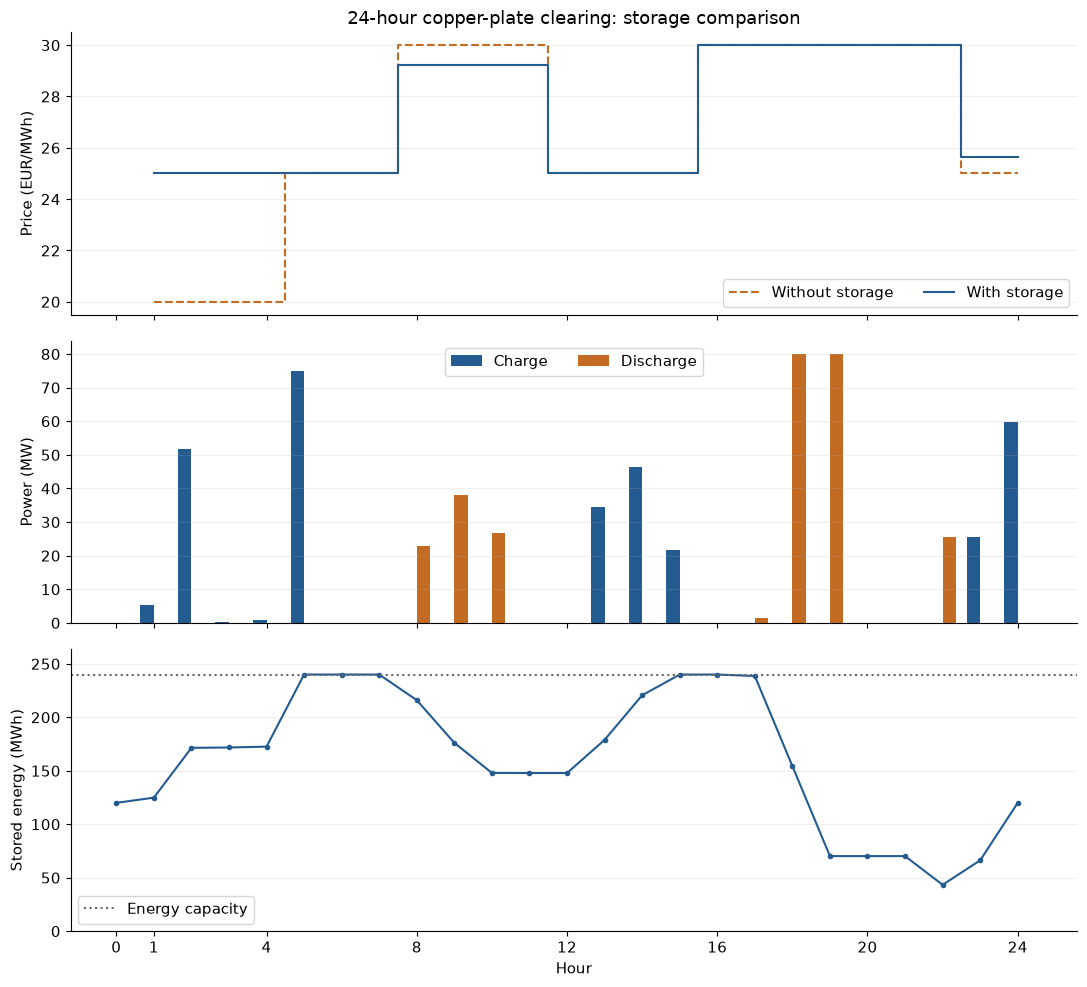

In [21]:
fig,axes=plt.subplots(3,1,figsize=(11,10),sharex=True)
axes[0].step(data['hours'],without['prices'][:,0],where='mid',label='Without storage',color=ORANGE,linestyle='--')
axes[0].step(data['hours'],with_battery['prices'][:,0],where='mid',label='With storage',color=BLUE)
axes[0].set_ylabel('Price (EUR/MWh)'); axes[0].legend(ncol=2)
axes[0].set_title('24-hour copper-plate clearing: storage comparison')
axes[1].bar(data['hours']-.18,a['ch'],width=.36,label='Charge',color=BLUE)
axes[1].bar(data['hours']+.18,a['dis'],width=.36,label='Discharge',color=ORANGE)
axes[1].set_ylabel('Power (MW)'); axes[1].legend(ncol=2)
axes[2].plot(np.arange(25),np.r_[st['initial'],a['e']],marker='o',markersize=3,color=BLUE)
axes[2].axhline(st['energy'],color='0.4',linestyle=':',label='Energy capacity')
axes[2].set_ylabel('Stored energy (MWh)');axes[2].set_xlabel('Hour');axes[2].set_ylim(0,st['energy']*1.1)
axes[2].set_xticks([0,1,4,8,12,16,20,24]);axes[2].legend()
for ax in axes: ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'storage_prices.png',dpi=150);plt.show()

## 4. 总福利及各参与者利润
对每个时段按相应统一电价结算，利润扣除实际出力的线性变动成本。福利分解中必须包含储能利润。

In [22]:
profits = data['supply'][['id','kind']].copy()
profits['without_storage_eur']=without['generator_profit']
profits['with_storage_eur']=with_battery['generator_profit']
summary = pd.DataFrame({
    'without_storage': [without['welfare'],without['generator_profit'].sum(),without['load_utility'].sum(),0.],
    'with_storage': [with_battery['welfare'],with_battery['generator_profit'].sum(),with_battery['load_utility'].sum(),with_battery['storage_profit']],
},index=['social_welfare_eur','generator_profit_eur','load_utility_eur','storage_profit_eur'])
display(summary);display(profits)
assert abs(with_battery['welfare']-with_battery['generator_profit'].sum()
           -with_battery['load_utility'].sum()-with_battery['storage_profit'])<1e-5

,without_storage,with_storage
social_welfare_eur,"1,268,436.2541","1,268,732.4765"
generator_profit_eur,"51,650.5083","54,724.2030"
load_utility_eur,"1,216,785.7457","1,213,921.6068"
storage_profit_eur,0.0000,86.6667


,id,kind,without_storage_eur,with_storage_eur
0,G_bus1,conventional,0.0000,0.0000
1,G_bus2,conventional,"21,700.0000","24,256.2690"
2,G_bus3,conventional,"5,500.0000","5,325.9064"
3,G_bus6,conventional,0.0000,0.0000
4,G_bus8,conventional,0.0000,0.0000
5,W_bus6,wind,"14,231.5822","14,505.0940"
6,W_bus8,wind,"10,218.9261","10,636.9336"


## 5. 储能为何能影响边际价格？

令 $v_t$ 为每增加 1 MWh 储能电量的机会价值（€/MWh）。在储能功率变量不触及界限时：

$$p_t^{ch}>0\text{ 且未满充功率}\Rightarrow\lambda_t=\eta^{ch}v_t,$$
$$p_t^{dis}>0\text{ 且未满放功率}\Rightarrow\lambda_t=v_t/\eta^{dis}.$$

若电量在相邻时段未触及界限，则 $v_t=v_{t+1}$；容量约束绑定时，该价值可发生变化。因此，若常规机组都在边界，电价可以由储能跨期机会成本决定，不一定等于当时任一常规机组报价。退化最优解下对偶电价也可能不唯一，不应仅凭价格波动范围断言储能必然削峰。

下面提取储能动态等式 marginal 的负值作为 $v_t$，并只在相应变量严格处于上下界之间时检查上述等式。

In [23]:
v = -with_battery['raw'].eqlin.marginals[with_battery['energy_rows']]
price = with_battery['prices'][:,0]
interior_ch=(a['ch']>TOL)&(a['ch']<st['power_ch']-TOL)
interior_dis=(a['dis']>TOL)&(a['dis']<st['power_dis']-TOL)
assert np.max(np.abs(price[interior_ch]-st['eta_ch']*v[interior_ch]),initial=0)<TOL
assert np.max(np.abs(price[interior_dis]-v[interior_dis]/st['eta_dis']),initial=0)<TOL
supply_cost=data['supply'].cost.to_numpy()
interior_g=(a['p']>TOL)&(a['p']<data['gmax']-TOL)
for t,g in zip(*np.where(interior_g)):
    assert abs(price[t]-supply_cost[g])<TOL
not_offer = np.min(np.abs(price[:,None]-supply_cost),axis=1)>TOL
pricing = pd.DataFrame({'hour':data['hours'],'price':price,'inventory_value':v,
    'interior_charge':interior_ch,'interior_discharge':interior_dis,
    'price_not_equal_to_supply_offer':not_offer})
display(pricing)
# Independent check: value of one extra 0.001 MW of demand in a selected hour.
t = int(np.flatnonzero(not_offer)[0]) if not_offer.any() else 11
eps=1e-3
plus=dispatch(data,demand_rhs=(t,0,eps))
minus=dispatch(data,demand_rhs=(t,0,-eps))
left=(minus['welfare']-with_battery['welfare'])/eps
right=(with_battery['welfare']-plus['welfare'])/eps
assert left-1e-4<=price[t]<=right+1e-4
print(f'第{t+1}小时需求扰动的左右边际价格：{left:.6f}, {right:.6f}；对偶电价：{price[t]:.6f}')
print(f"福利增加 {with_battery['welfare']-without['welfare']:.4f} €；储能利润 {with_battery['storage_profit']:.4f} €。")
print('有储能电价不等于任一供给报价的小时：',data['hours'][not_offer].tolist())
print(f"两种情况下价格标准差（不代表普遍定理）：{without['prices'][:,0].std():.4f} / {price.std():.4f}")
save_tables(OUT,inputs=inputs_table,hourly=comparison,profits=profits,summary=summary,storage_price_kkt=pricing)

,hour,price,inventory_value,interior_charge,interior_discharge,price_not_equal_to_supply_offer
0,1,25.0000,27.7778,True,False,False
1,2,25.0000,27.7778,True,False,False
2,3,25.0000,27.7778,True,False,False
3,4,25.0000,27.7778,True,False,False
4,5,25.0000,27.7778,True,False,False
5,6,25.0000,27.7778,False,False,False
6,7,25.0000,27.7778,False,False,False
7,8,29.2398,27.7778,False,True,True
8,9,29.2398,27.7778,False,True,True
9,10,29.2398,27.7778,False,True,True


第8小时需求扰动的左右边际价格：29.239766, 29.239766；对偶电价：29.239766
福利增加 296.2224 €；储能利润 86.6667 €。
有储能电价不等于任一供给报价的小时： [8, 9, 10, 11, 23, 24]
两种情况下价格标准差（不代表普遍定理）：3.6740 / 2.3234


## 结论范围
所有结论仅对应本例合成的 24 小时报价与预测。储能以同样初末电量参与，使无储能解仍是可行基准；本例福利改善由优化结果验证。具体逐时价格与参与者利润已保存为 CSV。

---

# 第四步：网络约束、节点电价、分区电价与物理可行性

## 目标

在第三步的同一组 24 小时数据和储能边界条件下，比较节点与分区市场；改变线路容量与 ATC；将分区出清注入放回完整 DC 网络，评估区内过载和所需调整量级。不求解再调度优化。

共享模型代码已内嵌于本文件，按从上到下顺序运行。输入来源为上传的作业 PDF、第一步 IEEE14 与第二步报价假设；所有新增限额均为明确的课程假设。

## 本次运行摘要

基准节点/分区模型总福利为 **1,245,517.0071 / 1,268,732.4765 €**。基准 ATC 为 195 MW，两区价格相同，但节点价格仍分离；第 18 小时母线 3 的边际价格为 **104.2983 €/MWh**。分区计划回代完整 DC 网络后，区内最大过载 **47.1645 MW**，所需平衡发电调整规模的最大小时下界为 **110.2667 MW**，尚未求解可执行再调度方案。

## 1. DC 网络及模型

$$\sum_{i\in n}p_{it}+p^{dis}_{nt}-\sum_{j\in n}d_{jt}-p^{ch}_{nt}-\sum_\ell C_{n\ell}f_{\ell t}=0$$
$$f_{\ell t}=\frac{S_{base}}{X_\ell}(\theta_{from,t}-\theta_{to,t}),\quad -F_\ell\le f_{\ell t}\le F_\ell.$$

采用第一步的全部 **15 条线路 + 5 台变压器**连接关系。按题目允许的简化，所有支路 $X_\ell=0.002$ p.u.，$S_{base}=100$ MVA，变压器变比取 1、相移取 0，忽略网损和无功。母线 1 相角固定为 0，相角单位 rad。保留第三步储能与 24 小时耦合。

**额定容量是新增假设，非 IEEE 原始热稳数据**：与母线 2 相连的每条支路限额 25 MW，其他支路 65 MW，使瓶颈可被观察。主灵敏度将所有支路限额统一乘以 0.5、1、2、10，保留电抗不变。

节点电价为节点平衡等式的 marginal / Δt，无约束时各节点价格相同。阻塞时电价由全网边际供给、潮流分布与约束影子价格共同决定，并不要求等于本地机组报价。

In [24]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.figsize': (10,4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GOLD = '#245b91', '#c46b23', '#9b7d23'
data = inputs()
OUT=Path('step4_results');OUT.mkdir(exist_ok=True)
display(data['edges'])
nodal=dispatch(data,mode='nodal')
copper=dispatch(data,mode='copper')
assert nodal['welfare']<=copper['welfare']+TOL
nodal_prices=pd.DataFrame(nodal['prices'],index=data['hours'],columns=[f'bus{b}' for b in range(1,15)])
nodal_prices.index.name='hour'
display(nodal_prices)
display(nodal['checks'].to_frame('KKT_residual'))

,id,from_bus,to_bus,kind,x_pu,limit_mw
0,L01,1,2,line,0.0020,25.0000
1,L02,1,5,line,0.0020,65.0000
2,L03,2,3,line,0.0020,25.0000
3,L04,2,4,line,0.0020,25.0000
4,L05,2,5,line,0.0020,25.0000
5,L06,3,4,line,0.0020,65.0000
6,L07,4,5,line,0.0020,65.0000
7,L08,6,11,line,0.0020,65.0000
8,L09,6,12,line,0.0020,65.0000
9,L10,6,13,line,0.0020,65.0000


,bus1,bus2,bus3,bus4,bus5,bus6,bus7,bus8,bus9,bus10,bus11,bus12,bus13,bus14
hour,,,,,,,,,,,,,,
1,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
2,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
3,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
4,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
5,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
6,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
7,24.9761,20.0000,30.6100,41.2201,29.9522,33.6124,40.0000,40.0000,38.7799,37.0574,35.3349,34.2584,34.9043,36.8421
8,25.4833,20.0000,31.6916,43.3831,30.9666,35.0000,42.0387,40.0000,40.6942,38.7961,36.8981,35.7118,36.4236,38.5589
9,25.4833,20.0000,31.6916,43.3831,30.9666,35.0000,42.0387,40.0000,40.6942,38.7961,36.8981,35.7118,36.4236,38.5589


,KKT_residual
equality_residual,0.0000
bounds_violation,0.0000
dual_sign_violation,0.0000
stationarity_residual,0.0000
lower_complementarity,0.0000
upper_complementarity,0.0000
strong_duality_relative_gap,0.0000


## 2. 节点电价与阻塞
热图保留全部 14 节点和 24 小时。下表记录绑定支路数和最大价格差；价格分离应与网络瓶颈一起解释。

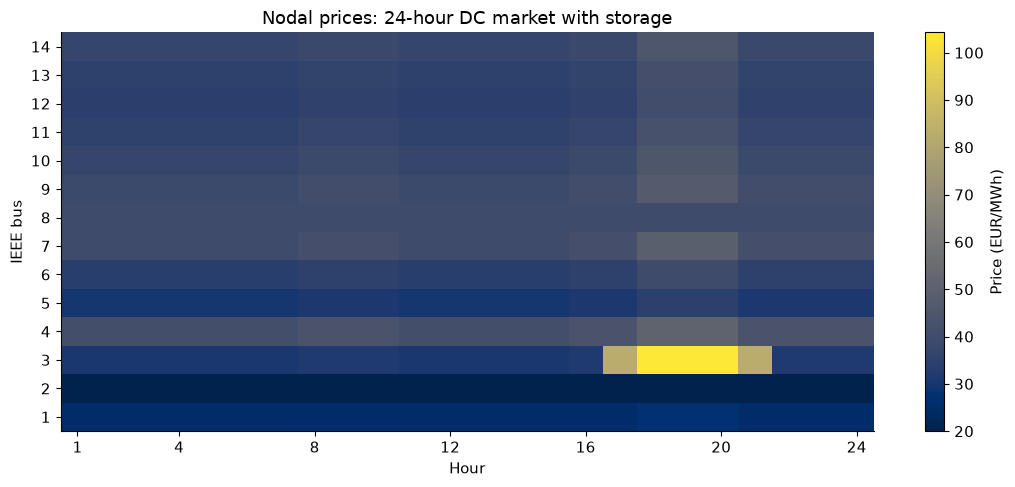

,hour,min_price,max_price,price_spread,binding_branches
0,1,20.0000,41.2201,21.2201,1
1,2,20.0000,41.2201,21.2201,1
2,3,20.0000,41.2201,21.2201,1
3,4,20.0000,41.2201,21.2201,1
4,5,20.0000,41.2201,21.2201,1
5,6,20.0000,41.2201,21.2201,1
6,7,20.0000,41.2201,21.2201,1
7,8,20.0000,43.3831,23.3831,2
8,9,20.0000,43.3831,23.3831,2
9,10,20.0000,43.3831,23.3831,2


第18小时，母线3的价格 104.2983，需求扰动左右斜率 104.2983/104.2983。


In [25]:
fig,ax=plt.subplots(figsize=(11,5))
im=ax.imshow(nodal['prices'].T,origin='lower',aspect='auto',cmap='cividis',extent=[.5,24.5,.5,14.5])
ax.set_xticks([1,4,8,12,16,20,24]);ax.set_yticks(range(1,15))
ax.set_xlabel('Hour');ax.set_ylabel('IEEE bus');ax.set_title('Nodal prices: 24-hour DC market with storage')
fig.colorbar(im,ax=ax,label='Price (EUR/MWh)');fig.tight_layout()
fig.savefig(OUT/'nodal_prices.png',dpi=150);plt.show()
flow=nodal['arrays']['f'];limits=data['edges'].limit_mw.to_numpy()
network_hourly=pd.DataFrame({'hour':data['hours'],
    'min_price':nodal['prices'].min(axis=1),'max_price':nodal['prices'].max(axis=1),
    'price_spread':np.ptp(nodal['prices'],axis=1),
    'binding_branches':np.isclose(np.abs(flow),limits,atol=1e-5).sum(axis=1)})
display(network_hourly)
# Confirm an additional small demand has a marginal welfare cost within price slopes.
t=int(np.argmax(np.ptp(nodal['prices'],axis=1))); n=int(np.argmax(nodal['prices'][t])); eps=1e-3
plus=dispatch(data,mode='nodal',demand_rhs=(t,n,eps))
minus=dispatch(data,mode='nodal',demand_rhs=(t,n,-eps))
left=(minus['welfare']-nodal['welfare'])/eps
right=(nodal['welfare']-plus['welfare'])/eps
assert left-1e-4<=nodal['prices'][t,n]<=right+1e-4
print(f'第{t+1}小时，母线{n+1}的价格 {nodal["prices"][t,n]:.4f}，需求扰动左右斜率 {left:.4f}/{right:.4f}。')
# DC recomputation independently checks the optimized phase-flow equations.
recomputed,_=physical_flows(data,nodal)
assert np.max(np.abs(recomputed-flow))<TOL

## 3. 线路容量灵敏度
保持负荷、报价、储能参数、电抗及拓扑相同，仅放大或缩小所有线路和变压器的容量。福利随可行域扩张应不降低；价格差不承诺逐小时单调。

,capacity_factor,welfare_eur,max_price_spread,mean_price_spread,unserved_mwh
0,0.5000,"1,193,390.3501",220.0000,120.4780,187.1510
1,1.0000,"1,245,517.0071",84.2983,33.2354,0.0000
2,2.0000,"1,267,966.5193",14.1049,4.3300,0.0000
3,10.0000,"1,268,732.4765",0.0000,0.0000,0.0000


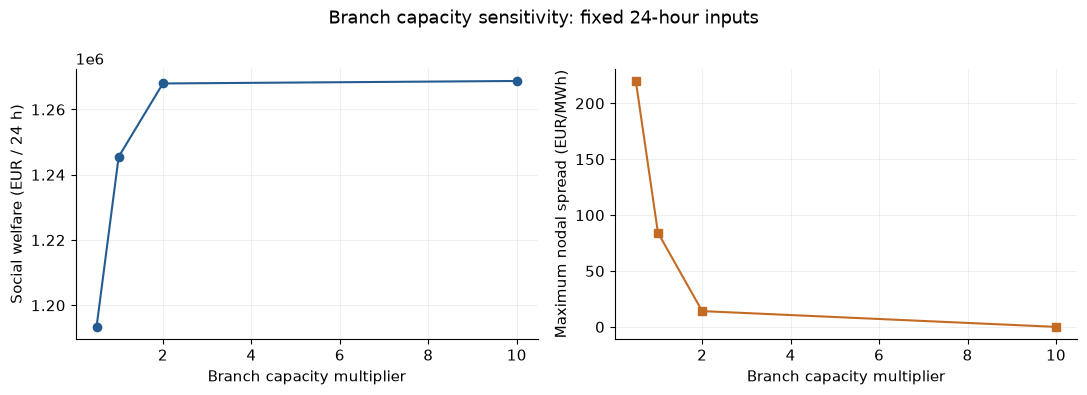

In [26]:
factors=[.5,1.,2.,10.]
nodal_cases={f: (nodal if f==1 else dispatch(data,mode='nodal',capacity_factor=f)) for f in factors}
sensitivity=pd.DataFrame([{'capacity_factor':f,'welfare_eur':r['welfare'],
    'max_price_spread':np.ptp(r['prices'],axis=1).max(),
    'mean_price_spread':np.ptp(r['prices'],axis=1).mean(),
    'unserved_mwh':(data['dmax']-r['arrays']['d']).sum()} for f,r in nodal_cases.items()])
assert (np.diff(sensitivity.welfare_eur)>=-TOL).all()
assert abs(nodal_cases[10.]['welfare']-copper['welfare'])<1e-4
assert np.max(np.ptp(nodal_cases[10.]['prices'],axis=1))<TOL
display(sensitivity)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(factors,sensitivity.welfare_eur,marker='o',color=BLUE)
axes[0].set_ylabel('Social welfare (EUR / 24 h)')
axes[1].plot(factors,sensitivity.max_price_spread,marker='s',color=ORANGE)
axes[1].set_ylabel('Maximum nodal spread (EUR/MWh)')
for ax in axes:ax.set_xlabel('Branch capacity multiplier');ax.grid(alpha=.2)
fig.suptitle('Branch capacity sensitivity: fixed 24-hour inputs');fig.tight_layout()
fig.savefig(OUT/'capacity_sensitivity.png',dpi=150);plt.show()

## 4. 两分区市场与 ATC 灵敏度

- A 区：IEEE 母线 1–5；B 区：母线 6–14。
- 基准 ATC = 跨区物理支路（含变压器）的容量之和；两区用一条可正反流动的运输连接，$|f^{AB}_t|\le ATC$。
- 分区模型忽略区内潮流与限额；每区一个平衡式，其对偶值为分区电价。储能仍位于 B 区。
- ATC 取基准的 0.10、0.25、0.5、1、2 倍。ATC 总和只是题目允许的近似，不能保证物理安全，也不能将区间商业交换直接当作每条物理线潮流。

跨区支路及容量：


,id,from_bus,to_bus,kind,x_pu,limit_mw
15,L16,4,7,transformer,0.0020,65.0000
16,L17,4,9,transformer,0.0020,65.0000
17,L18,5,6,transformer,0.0020,65.0000


基准 ATC： 195.0 MW


,ATC_factor,ATC_mw,welfare_eur,mean_price_A,mean_price_B,max_zonal_spread
0,0.1000,19.5000,"1,262,775.6044",25.4167,34.5771,15.0000
1,0.2500,48.7500,"1,267,659.9781",27.2917,29.8698,10.0000
2,0.5000,97.5000,"1,268,729.9165",27.1920,27.2191,0.6500
3,1.0000,195.0000,"1,268,732.4765",27.2191,27.2191,0.0000
4,2.0000,390.0000,"1,268,732.4765",27.2191,27.2191,0.0000


,zone_A,zone_B
1,25.0000,25.0000
2,25.0000,25.0000
3,25.0000,25.0000
4,25.0000,25.0000
5,25.0000,25.0000
6,25.0000,25.0000
7,25.0000,25.0000
8,29.2398,29.2398
9,29.2398,29.2398
10,29.2398,29.2398


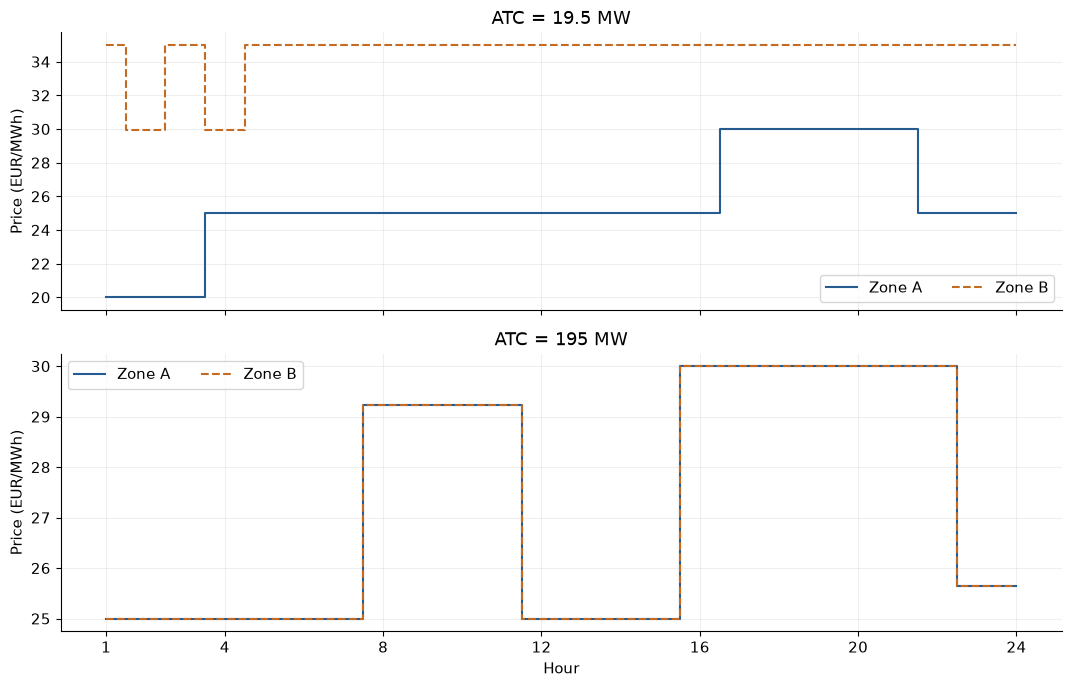

In [27]:
cut=data['edges'].loc[(data['edges'].from_bus<=5)!=(data['edges'].to_bus<=5)]
print('跨区支路及容量：');display(cut)
base_atc=float(cut.limit_mw.sum());print('基准 ATC：',base_atc,'MW')
atc_factors=[.1,.25,.5,1.,2.]
zonal_cases={f:dispatch(data,mode='zonal',atc_factor=f) for f in atc_factors}
zonal=zonal_cases[1.]
atc_summary=pd.DataFrame([{'ATC_factor':f,'ATC_mw':base_atc*f,'welfare_eur':r['welfare'],
    'mean_price_A':r['prices'][:,0].mean(),'mean_price_B':r['prices'][:,1].mean(),
    'max_zonal_spread':np.abs(r['prices'][:,0]-r['prices'][:,1]).max()}
    for f,r in zonal_cases.items()])
assert (np.diff(atc_summary.welfare_eur)>=-TOL).all()
assert zonal['welfare']>=nodal['welfare']-TOL
assert zonal['welfare']<=copper['welfare']+TOL
display(atc_summary)
zone_prices=pd.DataFrame(zonal['prices'],index=data['hours'],columns=['zone_A','zone_B'])
display(zone_prices)
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for f in [.1,1.]:
    r=zonal_cases[f]
    for n,colour in enumerate([BLUE,ORANGE]):
        axes[0 if f==.1 else 1].step(data['hours'],r['prices'][:,n],where='mid',color=colour,
            linestyle='-' if n==0 else '--',label=['Zone A','Zone B'][n])
    ax=axes[0 if f==.1 else 1];ax.set_title(f'ATC = {f*base_atc:g} MW');ax.set_ylabel('Price (EUR/MWh)');ax.legend(ncol=2);ax.grid(alpha=.2)
axes[1].set_xlabel('Hour');axes[1].set_xticks([1,4,8,12,16,20,24])
fig.tight_layout();fig.savefig(OUT/'zonal_atc_prices.png',dpi=150);plt.show()

## 5. 节点制与分区制：利润、福利与阻塞租金
两模型使用同一组参与者、初末电量和线性成本。不同位置电价结算时，消费者剩余 + 发电利润 + 储能利润 + 输电阻塞租金 = 社会福利，不能遗漏阻塞租金。

In [28]:
profits=data['supply'][['id','bus','kind']].copy()
profits['nodal_profit_eur']=nodal['generator_profit']
profits['zonal_profit_eur']=zonal['generator_profit']
profits['zonal_minus_nodal']=profits.zonal_profit_eur-profits.nodal_profit_eur
display(profits)
welfare_comparison=pd.DataFrame({
    label:[r['welfare'],r['generator_profit'].sum(),r['load_utility'].sum(),r['storage_profit'],r['rent']]
    for label,r in [('nodal',nodal),('zonal',zonal)]
},index=['welfare_eur','generator_profit_eur','load_utility_eur','storage_profit_eur','congestion_rent_eur'])
display(welfare_comparison)
# Verify positive economic rent against physical price differences times scheduled flows.
for r in [nodal,zonal]:
    buses=r['buses'];pos={b:i for i,b in enumerate(buses)}
    price_delta=np.column_stack([r['prices'][:,pos[row.to_bus]]-r['prices'][:,pos[row.from_bus]]
                                for _,row in r['model_edges'].iterrows()])
    rent_from_flows=float((price_delta*r['arrays']['f']).sum())
    assert abs(rent_from_flows-r['rent'])<1e-5

,id,bus,kind,nodal_profit_eur,zonal_profit_eur,zonal_minus_nodal
0,G_bus1,1,conventional,0.0000,0.0000,0.0000
1,G_bus2,2,conventional,0.0000,"24,256.2690","24,256.2690"
2,G_bus3,3,conventional,"46,848.8675","5,325.9064","-41,522.9611"
3,G_bus6,6,conventional,"1,500.7152",0.0000,"-1,500.7152"
4,G_bus8,8,conventional,0.0000,0.0000,0.0000
5,W_bus6,6,wind,"18,538.7071","14,505.0940","-4,033.6130"
6,W_bus8,8,wind,"15,826.0550","10,636.9336","-5,189.1215"


,nodal,zonal
welfare_eur,"1,245,517.0071","1,268,732.4765"
generator_profit_eur,"82,714.3448","54,724.2030"
load_utility_eur,"1,121,021.1411","1,213,921.6068"
storage_profit_eur,255.2395,86.6667
congestion_rent_eur,"41,526.2818",-0.0000


## 6. 分区出清的区内可行性与调整量级

冻结分区的逐时发电、用电和储能计划，在完整 DC 网络求解线性方程：$B_{bus}\theta=\mathrm{injection}$。这只是潮流回代，不做再调度。逐条比较 $|f|$ 与原始限额，分别报告区内、跨区过载。

**量级指标**：最大区内过载 MW、过载支路数、24 小时累计超限 MWh（各支路超限的绝对量相加）。最后一个指标是支路暴露量，**不是再调度电量**。

另给出保守的调整功率下界：对过载支路 $\ell$，一次从常规/风电机组所在母线 $a$ 向 $b$ 转移 1 MW 的注入最多改变 $\max(H_{\ell,a})-\min(H_{\ell,a})$ MW 的线流。固定负荷和储能计划、允许所有发电母线之间调整时，每小时所需的平衡发电调整规模（总上调量 = 总下调量）至少为
$$\max_{\ell\in\mathrm{internal}}\frac{(|f_{\ell}|-F_\ell)_+}{\max_a H_{\ell,a}-\min_a H_{\ell,a}}.$$
这是乐观下界，不考虑容量余量；不是可执行再调度方案，也不是最优值或上界。

In [29]:
physical,H=physical_flows(data,zonal)
over=np.maximum(np.abs(physical)-data['edges'].limit_mw.to_numpy(),0.)
internal=((data['edges'].from_bus<=5)==(data['edges'].to_bus<=5)).to_numpy()
source_buses=np.unique(data['supply'].bus.to_numpy(dtype=int)-1)
transfer_effect=np.ptp(H[:,source_buses],axis=1)
assert np.all(transfer_effect[internal]>0)
redispatch_lower=(over[:,internal]/transfer_effect[internal]).max(axis=1)
feasibility=pd.DataFrame({'hour':data['hours'],
    'max_internal_overload_mw':over[:,internal].max(axis=1),
    'internal_overloaded_branches':(over[:,internal]>TOL).sum(axis=1),
    'max_cross_border_overload_mw':over[:,~internal].max(axis=1),
    'generation_transfer_lower_bound_mw':redispatch_lower})
display(feasibility)
physical_flows_table=pd.DataFrame(physical,index=data['hours'],columns=data['edges'].id)
print(f"分区账面福利 - 节点福利 = {zonal['welfare']-nodal['welfare']:.4f} €；它不代表可物理实现的福利增量。")
print(f"区内最大过载 {over[:,internal].max():.4f} MW；区内累计支路超限暴露 {over[:,internal].sum():.4f} MWh。")
print(f"所需平衡发电调整规模的最大小时下界 {redispatch_lower.max():.4f} MW；具体可行方案未求解。")
assert np.max(np.abs(nodal['arrays']['f'])-limits)<TOL
print('节点出清满足所有线容量；分区出清是否满足区内线容量：',bool((over[:,internal]<=TOL).all()))
save_tables(OUT,branches=data['edges'],nodal_prices=nodal_prices,zonal_prices=zone_prices,
            capacity_sensitivity=sensitivity,atc_sensitivity=atc_summary,profits=profits,
            welfare=welfare_comparison,physical_flows=physical_flows_table,feasibility=feasibility)
# Full hourly prices for every capacity / ATC sensitivity, not only average prices.
for f,r in nodal_cases.items():
    pd.DataFrame(r['prices'],index=data['hours'],columns=nodal_prices.columns).to_csv(OUT/f'nodal_prices_capacity_{f:g}.csv')
for f,r in zonal_cases.items():
    pd.DataFrame(r['prices'],index=data['hours'],columns=['zone_A','zone_B']).to_csv(OUT/f'zonal_prices_atc_{f:g}.csv')

,hour,max_internal_overload_mw,internal_overloaded_branches,max_cross_border_overload_mw,generation_transfer_lower_bound_mw
0,1,24.9991,2,0.0000,40.7512
1,2,25.4842,2,0.0000,41.5420
2,3,26.1894,2,0.0000,42.6916
3,4,19.6021,3,0.0000,45.8281
4,5,27.8511,2,0.0000,65.1136
5,6,16.5471,3,0.0000,38.6857
6,7,19.5523,3,0.0000,45.7118
7,8,16.9225,3,0.0000,39.5633
8,9,15.5830,3,0.0000,36.4317
9,10,16.9690,3,0.0000,39.6721


分区账面福利 - 节点福利 = 23215.4694 €；它不代表可物理实现的福利增量。
区内最大过载 47.1645 MW；区内累计支路超限暴露 983.2054 MWh。
所需平衡发电调整规模的最大小时下界 110.2667 MW；具体可行方案未求解。
节点出清满足所有线容量；分区出清是否满足区内线容量： False


## 解释范围
无阻塞时统一边际价格可传播到全网；阻塞时注入一单位负荷所需的全网调节组合不同，即使本地无部分出清机组也会有明确节点电价。放宽 ATC 可提高忽略区内约束的账面福利，却不自动恢复物理可行性。以上只讨论无损 DC 近似，不能代替 AC 电压、无功或安全校核。

### 结合数值解释节点与分区差别

第 18 小时母线 3 的本地常规机组报价仅为 25 €/MWh，而该母线价格为 104.2983 €/MWh；本地机组已受 100 MW 上限限制。新增本地需求需要在受限的全网潮流中调整供给，故边际成本可高于本地报价。代码用该节点额外需求的左右有限差分直接验证了 104.2983 €/MWh。

把所有支路容量扩大至 10 倍后，各节点价格重新一致、总福利与无网络约束基准相同。ATC 从 19.5 MW 扩至 195 MW 时，分区价差消失；但这只放松区域商业交换约束，忽略的区内瓶颈仍在，因此更高的分区账面福利不能直接兑现。

---

# 第五步：储能利润最大化、KKT 与市场均衡

原题第五步写“第 2 步中的储能”，但第二步没有储能，第三步才引入。本 Notebook 明确采用**第三步 24 小时储能模型**；若教师要求单时段，只需令 $T=1$ 并保留相应库存边界条件。本步骤按原题无需仿真或编程，故只有推导单元。

## 1. 价格接受者的储能利润最大化

给定市场价格 $\lambda_t$，储能选择 $p_t^{ch},p_t^{dis},e_t$，无固定/退化成本：

$$\max\;\Pi^{S}=\sum_{t=1}^{T}\Delta t\,\lambda_t(p_t^{dis}-p_t^{ch})$$

满足
$$0\le p_t^{ch}\le P^{ch},\quad0\le p_t^{dis}\le P^{dis},\quad0\le e_t\le E,$$
$$h_t=e_t-e_{t-1}-\Delta t\eta^{ch}p_t^{ch}+\Delta t p_t^{dis}/\eta^{dis}=0,$$
$$e_0=E_0,\qquad e_T=E_T.$$

采用第三步边界：$E_0=E_T=120$ MWh。$e_0$ 是固定参数，$e_T=E_T$ 作为等式处理；不是给初始库存免费定价。储能是价格接受者，不能在自身优化中操控 $\lambda_t$。

## 2. 拉格朗日函数及符号约定

将目标写成最小化负利润。下界乘子为 $\alpha^{ch}_t,\alpha^{dis}_t,\alpha^e_t\ge0$；上界乘子为 $\beta^{ch}_t,\beta^{dis}_t,\beta^e_t\ge0$；动态等式乘子取 $-v_t$，终端等式乘子为自由变量 $\kappa$：

$$L=\sum_t\Delta t\lambda_t(p_t^{ch}-p_t^{dis})-\sum_tv_th_t+\kappa(e_T-E_T)$$
$$+\sum_t[-\alpha_t^{ch}p_t^{ch}+\beta_t^{ch}(p_t^{ch}-P^{ch})
-\alpha_t^{dis}p_t^{dis}+\beta_t^{dis}(p_t^{dis}-P^{dis})
-\alpha_t^ee_t+\beta_t^e(e_t-E)].$$

$v_t$ 可解释为储能库存的边际机会价值。不同资料可能采用相反的等式乘子符号，经济含义需按拉格朗日函数一致转换。

## 3. KKT 条件

### 原始可行

所有上述功率/电量上下界、储能动态方程及固定初末电量均成立。

### 对偶可行

$$\alpha_t^{ch},\beta_t^{ch},\alpha_t^{dis},\beta_t^{dis},\alpha_t^e,\beta_t^e\ge0,$$
$v_t$ 和 $\kappa$ 不限符号。

### 驻点条件

$$\Delta t(\lambda_t-\eta^{ch}v_t)-\alpha_t^{ch}+\beta_t^{ch}=0,$$
$$\Delta t(-\lambda_t+v_t/\eta^{dis})-\alpha_t^{dis}+\beta_t^{dis}=0,$$
$$-v_t+v_{t+1}-\alpha_t^e+\beta_t^e=0,\qquad t<T,$$
$$-v_T+\kappa-\alpha_T^e+\beta_T^e=0.$$

终端驻点条件单独列出，不能误写一个不存在的 $v_{T+1}$。末时电量约束与末时上下界可能同时绑定，从而产生对偶退化；价格不唯一时仍可满足这些条件。

### 互补松弛

$$\alpha_t^{ch}p_t^{ch}=0,\quad\beta_t^{ch}(P^{ch}-p_t^{ch})=0,$$
$$\alpha_t^{dis}p_t^{dis}=0,\quad\beta_t^{dis}(P^{dis}-p_t^{dis})=0,$$
$$\alpha_t^ee_t=0,\quad\beta_t^e(E-e_t)=0.$$

## 4. 经济解释

- 部分充电且功率界限不绑定：$\lambda_t=\eta^{ch}v_t$。
- 部分放电且功率界限不绑定：$\lambda_t=v_t/\eta^{dis}$。
- 中间电量不在上下界：$v_t=v_{t+1}$，跨期机会价值相同。
- 充/放电功率上限、能量边界或终端条件绑定时，价格关系包含相应稀缺租金，不能简单将价格等同于当时某台常规机组报价。

仅有 $\eta^{ch}\ne\eta^{dis}$ 并不能在任意价格下保证不同时充放电。本次代码不添加整数变量，而是对实际 LP 解检查同时充放电；第三步所选正价格场景通过该检查。负价格等场景需重新分析，不能照搬结论。

## 5. 与社会福利最大化问题的等价关系

对每台常规机组（风电成本取 0）定义
$$\max_{0\le p_{it}\le\bar P_{it}}\sum_t\Delta t(\lambda_t-C_i)p_{it},$$
其负利润最小化的驻点条件为
$$\Delta t(C_i-\lambda_t)-\alpha^p_{it}+\beta^p_{it}=0.$$

每个价格弹性负荷定义
$$\max_{0\le d_{jt}\le\bar D_{jt}}\sum_t\Delta t(B_{jt}-\lambda_t)d_{jt},$$
其驻点条件为
$$\Delta t(\lambda_t-B_{jt})-\alpha^d_{jt}+\beta^d_{jt}=0.$$
两者还包括各自上下界的原始可行、对偶非负与互补松弛。

加上储能上述 KKT，以及每小时市场平衡
$$\sum_i p_{it}+p_t^{dis}-\sum_j d_{jt}-p_t^{ch}=0,$$
便得到竞争性均衡条件。这与第三步社会福利最大化问题的 KKT 一致：市场平衡的拉格朗日乘子提供统一电价。所有参与者可行集为凸多面体、目标线性且解可行有界时，LP 的 KKT/强对偶性使福利最优解可由一组均衡价格支持。

该等价性依赖价格接受、无非凸启停和无市场势力等假设；有整数启停费用时，不能直接保证只靠统一电价回收所有成本。

## 6. 若严格取单时段

令 $T=1$：库存方程仍约束净充放电；若同时固定 $E_1=E_0$，正价格且有损耗时最优解通常为零充放电，因此无法体现跨期套利。若放开末库存，又未给末库存价值，就可能免费消耗初始能量。第三步采用完整 24 小时及相同初末电量，正是为避免这类边界偏差。

---

# 第六步：机组停运、风电偏差与实时平衡市场

## 目标与假设

对应原题第六步。以第二步同样的**第 12 小时、无网络、无储能、单时段 1 小时**为日前基准；实时负荷固定为日前成交量。独立重算日前结果，避免依赖另一个内核的变量。

- 意外停运：`G_bus2`，实际出力为 0，不能提供平衡服务。它未发出的日前计划作为非指令偏差结算，不能又算作有偿下调。
- `W_bus6` 实际预测偏差 −15%，`W_bus8` +10%，并检查未超过装机容量。
- 默认灵活机组：`G_bus1` 和 `G_bus3`；其他常规机组除故障机组外保持日前计划。预留上下调能力由日前计划和额定容量决定，不另设备用市场。
- 上调报价 $a_i^{up}=\lambda^{DA}+0.10 C_i$；下调报价 $a_i^{down}=\lambda^{DA}-0.15 C_i$。
- 失负荷价值 VOLL = 500 €/MWh；不计固定/启动成本。平衡服务采用统一实时价格结算，不采用按报价支付。
- 本 Notebook 的主场景可由常规灵活机组处理，故不另设风电主动弃风平衡产品；若修改成无法通过常规下调消除的严重过剩，求解器会明确报不可行，应增加明确的弃风产品后再求解，不静默改变模型。

输入沿用前两步，相关合成数据不是实测市场数据。共享模型代码已内嵌于本文件，无需额外文件。

## 本次运行摘要

第 12 小时日前电价 **25 €/MWh**；故障及风电误差合成系统短缺 **143.4352 MW**，平衡电价 **28 €/MWh**，失负荷为 0。故障 G_bus2 利润为 −420 €；风场 W_bus8 帮助缓解短缺，单一/双价格利润分别为 423.4438 / 418.8743 €。逐参与者结算分项均在结果表及 CSV 中保留。

In [30]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.figsize': (10,4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GOLD = '#245b91', '#c46b23', '#9b7d23'
data = inputs()
from scipy.optimize import linprog
OUT=Path('step6_results');OUT.mkdir(exist_ok=True)
HOUR=12
TRIPPED_ID='G_bus2'
FLEXIBLE_IDS=['G_bus1','G_bus3']
WIND_FACTORS={'W_bus6':.85,'W_bus8':1.10}
VOLL=500.
DURATION_HOURS=1.
# Restore second-step input: unchanged original demand, flat bid 200 EUR/MWh.
da_data=dict(data)
da_data['dmax']=np.tile(data['loads'].base_mw.to_numpy(),(24,1))
da_data['bids']=np.full_like(da_data['dmax'],200.)
da=dispatch(da_data,with_storage=False,hour=HOUR)
assert abs(da['prices'][0,0]-25.)<TOL
p_da=da['arrays']['p'][0];load_da=da['arrays']['d'][0]
price_da=float(da['prices'][0,0]); supply=data['supply']
print('日前电价：',price_da,'€/MWh；成交负荷：',load_da.sum(),'MW')
display(supply[['id','bus','cost']].assign(day_ahead_mw=p_da))

日前电价： 25.0 €/MWh；成交负荷： 259.0 MW


,id,bus,cost,day_ahead_mw
0,G_bus1,1,30.0000,0.0000
1,G_bus2,2,20.0000,140.0000
2,G_bus3,3,25.0000,70.7125
3,G_bus6,6,35.0000,0.0000
4,G_bus8,8,40.0000,0.0000
5,W_bus6,6,0.0000,33.0557
6,W_bus8,8,0.0000,15.2318


## 1. 区分非指令偏差与平衡指令

记非指令偏差为 $\delta_i$（实际可用注入 − 日前计划，不含 ISO 指令）。风电有 $\delta_w=W^{actual}-p_w^{DA}$，故障机组有 $\delta_i=-p_i^{DA}$，正常常规机组为 0。系统缺口 $\Delta=-\sum_i\delta_i$，正值表示系统短缺。

BSP 上调/下调变量分别为 $u_i,v_i$，真实出力为 $p_i^{DA}+\delta_i+u_i-v_i$。明确区分两类调整，结算时才不会把 BSP 的执行指令再次作为不平衡罚款。

In [31]:
ids=supply.id.tolist(); G=len(ids)
assert TRIPPED_ID in ids and supply.iloc[ids.index(TRIPPED_ID)].kind=='conventional'
assert TRIPPED_ID not in FLEXIBLE_IDS
assert all(i in ids and supply.iloc[ids.index(i)].kind=='conventional' for i in FLEXIBLE_IDS)
delta=np.zeros(G)
delta[ids.index(TRIPPED_ID)]=-p_da[ids.index(TRIPPED_ID)]
wind_actual={}
for ident,factor in WIND_FACTORS.items():
    g=ids.index(ident)
    # Actual wind follows the first-step forecast, not an already-curtailed DA schedule.
    actual=data['gmax'][HOUR-1,g]*factor
    assert 0<=actual<=supply.iloc[g].capacity_mw
    wind_actual[ident]=actual
    delta[g]=actual-p_da[g]
assert p_da[ids.index(TRIPPED_ID)]>TOL, '选择实际有日前出力的故障机组。'
deficit=-float(delta.sum())
print(f'系统净缺口 {deficit:.6f} MW；正值=短缺，负值=过剩。')
display(pd.DataFrame({'id':ids,'day_ahead_mw':p_da,'uninstructed_deviation_mw':delta,
                     'available_before_balancing_mw':p_da+delta}))

系统净缺口 143.435174 MW；正值=短缺，负值=过剩。


,id,day_ahead_mw,uninstructed_deviation_mw,available_before_balancing_mw
0,G_bus1,0.0000,0.0000,0.0000
1,G_bus2,140.0000,-140.0000,0.0000
2,G_bus3,70.7125,0.0000,70.7125
3,G_bus6,0.0000,0.0000,0.0000
4,G_bus8,0.0000,0.0000,0.0000
5,W_bus6,33.0557,-4.9584,28.0973
6,W_bus8,15.2318,1.5232,16.7550


## 2. 平衡出清 LP 与价格

$$\min\Delta t\left(\sum_i a_i^{up}u_i-\sum_i a_i^{down}v_i+500\sum_j s_j\right)$$
$$\sum_i(u_i-v_i)+\sum_j s_j=\Delta,$$
$$0\le u_i\le P_i^{max}-p_i^{DA},\quad0\le v_i\le p_i^{DA},\quad0\le s_j\le d_j^{DA}.$$

只有灵活且未故障机组有非零调节上下限。$s_j$ 是强制失负荷，负荷不主动报价参与平衡。下调是系统回购/减少发电，故目标中为负的下调报价；BSP 的实际发电成本也要按下调后真实发电量计算。

平衡价格 $\lambda^{RT}$ 是该**缺口右端**的 marginal / Δt。检查全部 LP KKT，并通过增加少量系统缺口的目标增量核对价格。

In [32]:
flex=[ids.index(i) for i in FLEXIBLE_IDS]; K=len(flex); D=len(load_da)
cost=supply.cost.to_numpy()
up_bid=price_da+.10*cost[flex]
down_bid=price_da-.15*cost[flex]
up_max=supply.capacity_mw.to_numpy()[flex]-p_da[flex]
down_max=p_da[flex]
objective=DURATION_HOURS*np.r_[up_bid,-down_bid,np.full(D,VOLL)]
A=np.r_[np.ones(K),-np.ones(K),np.ones(D)].reshape(1,-1)
lo=np.zeros(2*K+D); hi=np.r_[up_max,down_max,load_da]

def balance_market(rhs):
    r=linprog(objective,A_eq=A,b_eq=[rhs],bounds=list(zip(lo,hi)),method='highs')
    if not r.success: raise RuntimeError('平衡出清失败，请检查故障规模与调节/弃风能力：'+r.message)
    return r

rt=balance_market(deficit)
price_rt=float(rt.eqlin.marginals[0])/DURATION_HOURS
up=rt.x[:K];down=rt.x[K:2*K];shed=rt.x[2*K:]
checks=validate_lp(rt,objective,A,np.array([deficit]),lo,hi)
assert np.max(np.minimum(up,down))<TOL
assert abs(up.sum()-down.sum()+shed.sum()-deficit)<TOL
u=np.zeros(G);v=np.zeros(G);u[flex]=up;v[flex]=down
actual=p_da+delta+u-v
assert abs(actual.sum()-(load_da.sum()-shed.sum()))<TOL
assert np.min(actual)>-TOL
assert np.max(actual-supply.capacity_mw.to_numpy())<TOL
assert abs(actual[ids.index(TRIPPED_ID)])<TOL
eps=1e-3
left=(rt.fun-balance_market(deficit-eps).fun)/(eps*DURATION_HOURS)
right=(balance_market(deficit+eps).fun-rt.fun)/(eps*DURATION_HOURS)
assert left-1e-4<=price_rt<=right+1e-4
regulation=pd.DataFrame({'id':FLEXIBLE_IDS,'up_bid':up_bid,'down_bid':down_bid,
                         'up_limit_mw':up_max,'down_limit_mw':down_max,'up_mw':up,'down_mw':down})
display(regulation);display(checks.to_frame('KKT_residual'))
print(f'平衡电价 {price_rt:.6f} €/MWh；有限差分 {left:.6f}/{right:.6f} €/MWh')
print(f'失负荷 {shed.sum():.6f} MWh；平衡 LP 净报价成本 {rt.fun:.6f} €。')

,id,up_bid,down_bid,up_limit_mw,down_limit_mw,up_mw,down_mw
0,G_bus1,28.0000,20.5000,332.4000,0.0000,114.1477,0.0000
1,G_bus3,27.5000,21.2500,29.2875,70.7125,29.2875,0.0000


,KKT_residual
equality_residual,0.0000
bounds_violation,0.0000
dual_sign_violation,0.0000
stationarity_residual,0.0000
lower_complementarity,0.0000
upper_complementarity,0.0000
strong_duality_relative_gap,0.0000


平衡电价 28.000000 €/MWh；有限差分 28.000000/28.000000 €/MWh
失负荷 0.000000 MWh；平衡 LP 净报价成本 4001.541142 €。


## 3. 单一价格与双价格不平衡结算

**单一价格**：所有非指令偏差 $\delta_i$ 都按 $\lambda^{RT}$ 结算。

**双价格**（本作业采用的明确约定）：

- 系统短缺：短偏差（$\delta_i<0$，加剧短缺）按 RT；长偏差（$\delta_i>0$，帮助系统）按 DA。
- 系统过剩：长偏差按 RT；短偏差按 DA。
- 无系统偏差：非指令偏差按 DA。

这是常见课程化双价格规则，不声称为特定交易所的完整结算细则。

对两种机制，**被指令的平衡服务**都单独按统一 RT 电价结算。总利润为
$$\Pi_i=\lambda^{DA}p_i^{DA}\Delta t+\lambda^{RT}(u_i-v_i)\Delta t
+\lambda_i^{imb}\delta_i\Delta t-C_i p_i^{actual}\Delta t.$$

故障机组需承担负偏差购买成本；即使实际出力为 0，也不能将其利润简单设为 0。风电零成本但仍承担/获得偏差结算。正常 BSP 只有指令、没有非指令偏差时，两种机制的利润应完全一致。

逐参与者总利润（完整结算分项见导出CSV）：


,id,kind,actual_mw,uninstructed_delta_mw,profit_single_eur,profit_dual_eur,dual_minus_single_eur
0,G_bus1,conventional,114.1477,0.0000,-228.2954,-228.2954,0.0000
1,G_bus2,conventional,0.0000,-140.0000,-420.0000,-420.0000,0.0000
2,G_bus3,conventional,100.0000,0.0000,87.8624,87.8624,0.0000
3,G_bus6,conventional,0.0000,0.0000,0.0000,0.0000,0.0000
4,G_bus8,conventional,0.0000,0.0000,0.0000,0.0000,0.0000
5,W_bus6,wind,28.0973,-4.9584,687.5583,687.5583,0.0000
6,W_bus8,wind,16.7550,1.5232,423.4438,418.8743,-4.5695


,profit_single_eur,profit_dual_eur
kind,,
conventional,-560.4329,-560.4329
wind,"1,111.0021","1,106.4326"


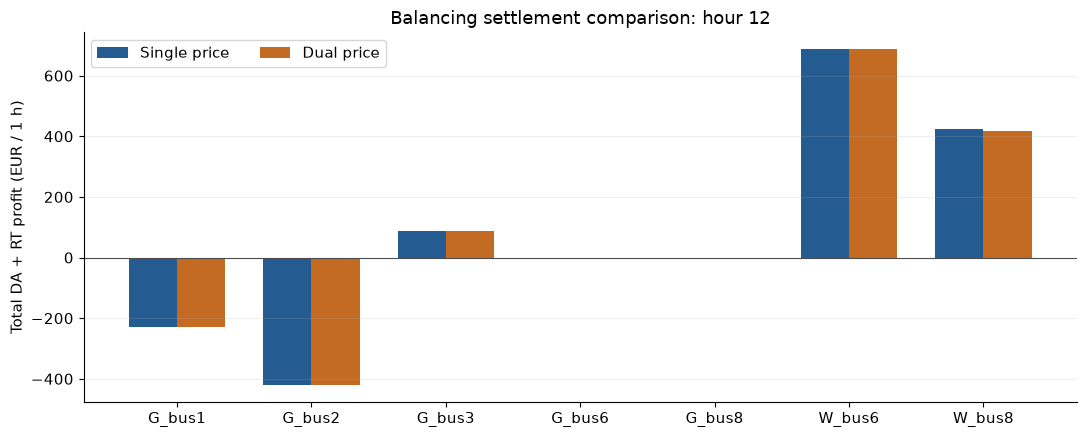

In [33]:
single_imb_price=np.full(G,price_rt)
if deficit>TOL:
    dual_imb_price=np.where(delta<0,price_rt,price_da)
elif deficit<-TOL:
    dual_imb_price=np.where(delta>0,price_rt,price_da)
else:
    dual_imb_price=np.full(G,price_da)
base_revenue=price_da*p_da*DURATION_HOURS
balancing_revenue=price_rt*(u-v)*DURATION_HOURS
production_cost=cost*actual*DURATION_HOURS
profit_single=base_revenue+balancing_revenue+single_imb_price*delta*DURATION_HOURS-production_cost
profit_dual=base_revenue+balancing_revenue+dual_imb_price*delta*DURATION_HOURS-production_cost
settlement=supply[['id','kind','cost']].copy()
for name,value in {
    'day_ahead_mw':p_da,'uninstructed_delta_mw':delta,'up_mw':u,'down_mw':v,'actual_mw':actual,
    'day_ahead_revenue_eur':base_revenue,'instruction_revenue_eur':balancing_revenue,
    'single_imb_price':single_imb_price,'dual_imb_price':dual_imb_price,
    'single_imb_cash_eur':single_imb_price*delta*DURATION_HOURS,
    'dual_imb_cash_eur':dual_imb_price*delta*DURATION_HOURS,
    'actual_cost_eur':production_cost,'profit_single_eur':profit_single,
    'profit_dual_eur':profit_dual,'dual_minus_single_eur':profit_dual-profit_single,
}.items(): settlement[name]=value
# Exact component reconciliation; do not count instructions a second time as imbalance.
assert np.max(np.abs((profit_dual-profit_single)-(dual_imb_price-price_rt)*delta*DURATION_HOURS))<TOL
assert np.max(np.abs(profit_single[flex]-profit_dual[flex]))<TOL
print('逐参与者总利润（完整结算分项见导出CSV）：')
display(settlement[['id','kind','actual_mw','uninstructed_delta_mw','profit_single_eur','profit_dual_eur','dual_minus_single_eur']])
display(settlement.groupby('kind')[['profit_single_eur','profit_dual_eur']].sum())
fig,ax=plt.subplots(figsize=(11,4.5));x=np.arange(G)
ax.bar(x-.18,profit_single,width=.36,label='Single price',color=BLUE)
ax.bar(x+.18,profit_dual,width=.36,label='Dual price',color=ORANGE)
ax.axhline(0,color='0.3',linewidth=.8);ax.set_xticks(x,ids)
ax.set_ylabel('Total DA + RT profit (EUR / 1 h)');ax.set_title(f'Balancing settlement comparison: hour {HOUR}')
ax.legend(ncol=2);ax.grid(axis='y',alpha=.2);fig.tight_layout()
fig.savefig(OUT/'settlement_profit.png',dpi=150);plt.show()

## 4. 对 BSP 与不平衡制造者的影响
只对已求解的场景作结论；若换成系统过剩，应重新求解、使用过剩对应的双价格分支，而不能沿用本次 RT 电价。

In [34]:
print(f'日前 {price_da:.4f} €/MWh，实时 {price_rt:.4f} €/MWh，缺口 {deficit:.4f} MW。')
print('BSP执行指令单独按RT结算；本例BSP没有非指令偏差，两机制利润相同。')
for g in np.flatnonzero(np.abs(delta)>TOL):
    effect='加剧' if delta[g]*deficit<0 else '缓解'
    print(f"{ids[g]}：{effect}系统不平衡，偏差 {delta[g]:+.4f} MW；单一/双价格利润 {profit_single[g]:.4f}/{profit_dual[g]:.4f} €。")
print('在本例短缺且RT高于DA时，帮助系统的正风电偏差在单一价格下获得更高奖励；双价格按DA结算。')
print('故障和短风电偏差均按RT承担缺额成本，二者在本例两机制中相同；这是场景相关结论。')
print('平衡报价成本、结算现金流和真实生产成本是不同口径，本Notebook分别列示。')
load_shedding=pd.DataFrame({'id':data['loads'].id,'day_ahead_mw':load_da,'shed_mw':shed,'served_rt_mw':load_da-shed})
summary=pd.Series({'hour':HOUR,'DA_price':price_da,'RT_price':price_rt,'deficit_mw':deficit,
                   'load_shedding_mwh':shed.sum()*DURATION_HOURS,
                   'profit_single_total_eur':profit_single.sum(),'profit_dual_total_eur':profit_dual.sum()})
save_tables(OUT,settlement=settlement,regulation=regulation,load_shedding=load_shedding,
            summary=summary.to_frame('value'),kkt=checks.to_frame('residual'))

日前 25.0000 €/MWh，实时 28.0000 €/MWh，缺口 143.4352 MW。
BSP执行指令单独按RT结算；本例BSP没有非指令偏差，两机制利润相同。
G_bus2：加剧系统不平衡，偏差 -140.0000 MW；单一/双价格利润 -420.0000/-420.0000 €。
W_bus6：加剧系统不平衡，偏差 -4.9584 MW；单一/双价格利润 687.5583/687.5583 €。
W_bus8：缓解系统不平衡，偏差 +1.5232 MW；单一/双价格利润 423.4438/418.8743 €。
在本例短缺且RT高于DA时，帮助系统的正风电偏差在单一价格下获得更高奖励；双价格按DA结算。
故障和短风电偏差均按RT承担缺额成本，二者在本例两机制中相同；这是场景相关结论。
平衡报价成本、结算现金流和真实生产成本是不同口径，本Notebook分别列示。


### 为什么某个 BSP 的利润为负？

本例 G_bus1 的实际边际生产成本为 30 €/MWh，但题目指定上调报价为 `25 + 0.10 × 30 = 28 €/MWh`，低于生产成本。该机组被调用 114.1477 MW，以 28 €/MWh 结算，因此利润为 **−228.2954 €**。这是忠实使用题目报价规则的结果，不是把成本漏算；不能为了使利润为正而改成“成本加成报价”。本例没有另加启用补偿或保底收入。与之相比 G_bus3 利润为 87.8624 €，故障 G_bus2 为 −420 €。

此处平衡报价按题目固定，未额外假设 BSP 可以在事后拒绝负利润指令；这与第五步所讨论的理想价格接受者自主利润最大化模型的前提应作区分。